# Capstone Project
## Predicting Six-Month Voluntary Attrition for Timely Retention Support

**Problem Statement:** Can monthly workforce information be used to identify employees with a higher relative likelihood of voluntary attrition during the following six months, so Kaiser Permanente HR leaders can focus timely retention support?

Voluntary exits can disrupt care and operations, raise hiring costs and add work for colleagues. I explore whether a focused review list gives HR a useful starting point. Cost savings and exits prevented need separate evaluation.

Each row represents an employee at a monthly snapshot. The target is `1` for a qualifying voluntary exit within six months and `0` otherwise. I compare the ranking with an untargeted list and look for workforce patterns worth reviewing.

In [2]:
import hashlib
import warnings

# Load tools for exploring data and presenting results.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Load preparation, modeling and evaluation tools.
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

from sklearn.base import clone


## 1. Starting with Monthly Workforce Records

I built `Attrition.Employee_Comp_Monthly` in SQL Server to combine monthly workforce information with the following six-month exit outcome.

The source has about 3.3 million employee-month records across three years. Employees can appear in several months. IDs are masked and excluded from model inputs. Saved aggregate results are available for review; a full rerun needs authorized SQL access and local settings.

**Scope:** Northern California and Executives. Other business units need separate evaluation. Job and organization fields help describe results, although development testing did not support keeping the tested organization categories as predictors.

In [3]:
# Use Windows authentication with local settings.
import json
import os
from pathlib import Path
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# Prefer an environment URL over the local file.
connection_url = os.environ.get("ATTRITION_SQLALCHEMY_URL")
if not connection_url:
    config_candidates = [
        Path("sql_connection.local.json"),
        Path("Final Report") / "sql_connection.local.json",
        Path("Capstone") / "Final Report" / "sql_connection.local.json",
    ]
    config_path = next((p for p in config_candidates if p.is_file()), None)
    if config_path is None:
        raise RuntimeError(
            "Open Jupyter in the Final Report folder containing "
            "sql_connection.local.json, or set ATTRITION_SQLALCHEMY_URL. "
            "Database access is required to reload the private workforce data."
        )
    settings = json.loads(config_path.read_text(encoding="utf-8"))
    connection_url = URL.create(
        "mssql+pyodbc",
        host=settings["server"],
        port=int(settings["port"]),
        database=settings["database"],
        query={
            "driver": settings.get("driver", "ODBC Driver 17 for SQL Server"),
            "trusted_connection": "yes",
        },
    )

engine = create_engine(connection_url, connect_args={"timeout": 15}, pool_pre_ping=True)
sql = """
EXEC Attrition.Employee_Comp_Monthly
    @snapshot_months_back = 36,
    @mask_nuid = 1,
    @regions = 'Northern California,Executives';
"""
df = pd.read_sql(sql, engine)
print("Rows loaded:", f"{len(df):,}")
print("Columns loaded:", df.shape[1])
print("Snapshots loaded:", df["snapshot_date"].nunique())

Rows loaded: 3,273,117
Columns loaded: 31
Snapshots loaded: 36


In [4]:
# Check for one record per employee per month.
employee_month_duplicate_count = int(
    df.duplicated(subset=["snapshot_date", "nuid"]).sum()
)
print("Duplicate employee-month records:", f"{employee_month_duplicate_count:,}")

if employee_month_duplicate_count > 0:
    raise ValueError(
        "The source contains duplicate employee-month records and must be corrected before modeling."
    )


Duplicate employee-month records: 0


## 2. Understanding the Data Before Modeling

I check dates, types, missing values and unusual ranges. The source has **3,273,117 employee-month records across 36 snapshots**, October 2023–September 2026.

Section 3 retains **2,548,054 records through January 2026** with complete outcomes. Evaluation uses a subset: 1,272,081 training records, 91,167 validation records and 90,988 historical-holdout records.

Because exits are rare, I focus on cases found and review workload rather than accuracy alone.

In [5]:
# Count records before filtering outcomes.
df.shape

(3273117, 31)

In [6]:
# Check missing inputs before filling them.
missing_value_review_columns = [
    "annual_salary",
    "compa_ratio",
    "performance_rating",
    "tenure_months",
    "low_performer",
    "mgr_team_size",
    "mgr_avg_team_tenure",
    "mgr_low_perf_pct",
    "mgr_attrition_6mo_rate",
    "mgr_attrition_12mo_rate",
    "region",
    "entity",
    "service_area_new",
    "attrition_6mo_voluntary",
]
missing_value_summary = (
    (df[missing_value_review_columns].isna().mean() * 100)
    .rename("missing_value_percent")
    .sort_values(ascending=False)
    .to_frame()
)
display(missing_value_summary.round(1))


,missing_value_percent
low_performer,24.1
performance_rating,24.1
attrition_6mo_voluntary,22.2
mgr_attrition_12mo_rate,14.9
annual_salary,12.6
mgr_attrition_6mo_rate,8.8
mgr_low_perf_pct,2.4
compa_ratio,0.9
service_area_new,0.0
mgr_team_size,0.0


I fill missing numeric inputs using values learned inside the training pipeline. Missing outcomes are different: an unknown six-month outcome cannot count as “no exit”. I check completeness by snapshot month.

In [7]:
# Summarize the data without displaying individual employee records.
summary_features = ["annual_salary", "tenure_months", "compa_ratio",
                    "performance_rating", "mgr_team_size"]
summary_labels = {
    "annual_salary": "Recorded annual salary (USD)",
    "tenure_months": "Employee tenure (months)",
    "compa_ratio": "Pay position relative to peers",
    "performance_rating": "Performance rating",
    "mgr_team_size": "Manager team size",
}
workforce_summary = df[summary_features].describe().T[
    ["mean", "25%", "50%", "75%", "max"]
].rename(index=summary_labels, columns={"mean": "Mean", "25%": "25th percentile",
    "50%": "Median", "75%": "75th percentile", "max": "Maximum"})
display(workforce_summary.round(2))

,Mean,25th percentile,Median,75th percentile,Maximum
Recorded annual salary (USD),120686.81,75953.03,110511.65,160049.05,2450000.06
Employee tenure (months),135.16,44.00,106.00,215.00,731.00
Pay position relative to peers,0.99,0.97,1.00,1.02,8.83
Performance rating,3.27,3.00,3.00,4.00,5.00
Manager team size,28.13,15.00,23.00,34.00,328.00


### Why an Uncommon Outcome Changes the Evaluation

Only about 1%–2% of records have a qualifying voluntary exit. With so few exits, a model can get most records right while overlooking the very group HR wants to understand. I need to judge whether the ranking finds more exit cases than an untargeted review and how much work that requires.

**Average precision (AP)** summarizes precision across the ranking and guides development. It is not the trapezoidal area under the precision-recall curve. **ROC-AUC** adds another view of separation.

For the list, **recall** means cases captured, **precision** means the observed exit share, and **lift** compares that share with the workforce rate. List size shows workload. I choose the cutoff on validation, then check it on the historical holdout.

In [8]:
# Check dates before splitting the records.
df['snapshot_date'].min(), df['snapshot_date'].max()

(datetime.date(2023, 10, 31), datetime.date(2026, 9, 30))

### Exploratory Findings Carried into Modeling

The [EDA summary](../EDA/README.md) found exits in around 1.3% of fully observed employee-months. Employees who later left had roughly three years of median tenure, versus nearly nine among those without the target exit. Pay-position differences were smaller. Workforce mix and repeated records limit causal conclusions about department and job-family patterns.

The earlier baseline had about 3.1% validation AP, but its different setup prevents a direct comparison with the final models. These findings guided checks of tenure, pay definitions and calendar-based performance. Unusual pay values need investigation before HR interpretation.

## 3. Making Sure the Forecast Uses the Right Information

I exclude identifiers and future termination details to prevent **data leakage**. Earlier six-month outcome windows must finish before the next forecast date.

A September 2026 snapshot does not guarantee complete earlier outcomes. I use the earlier of the latest snapshot minus six months and the latest eligible month with complete labels: **January 31, 2026** here.

This retains **2,548,054 labeled records** and excludes **725,063 recent or incomplete-coverage records**. Unknown outcomes are never filled as zero. The notebook stops if an incomplete month remains inside the retained history.

In [9]:
import pandas as pd
import numpy as np

TARGET_COL = "attrition_6mo_voluntary"
OUTCOME_WINDOW_MONTHS = 6


def shift_month_end(date_value, months):
    """Match the SQL target's month-end outcome boundary."""
    return (pd.Timestamp(date_value).to_period("M") + months).to_timestamp("M")


def determine_label_maturity(frame, target_col, outcome_window_months=6):
    """Require elapsed time and complete snapshot-wide label coverage."""
    if frame.empty:
        raise ValueError("No workforce records are available for modeling.")
    dates = pd.to_datetime(frame["snapshot_date"], errors="raise")
    if dates.isna().any() or not dates.dt.is_month_end.all():
        raise ValueError("Every workforce snapshot must have a valid month-end date.")
    target = frame[target_col]
    if not target.dropna().isin([0, 1]).all():
        raise ValueError("The attrition target must contain only 0, 1, or unavailable labels.")

    latest_snapshot = dates.max()
    calendar_cutoff = shift_month_end(latest_snapshot, -outcome_window_months)
    coverage = (pd.DataFrame({"snapshot_date": dates, "target": target})
                .groupby("snapshot_date")["target"].agg(rows="size", labeled_rows="count"))
    coverage["missing_targets"] = coverage["rows"] - coverage["labeled_rows"]
    coverage["calendar_eligible"] = coverage.index <= calendar_cutoff
    complete_dates = coverage.index[
        coverage["calendar_eligible"] & coverage["missing_targets"].eq(0)]
    if len(complete_dates) == 0:
        raise ValueError("No calendar-eligible snapshot has complete six-month outcomes.")
    latest_complete_snapshot = complete_dates.max()
    maturity_cutoff = min(calendar_cutoff, latest_complete_snapshot)
    coverage["retained_for_modeling"] = coverage.index <= maturity_cutoff

    incomplete_history = coverage.loc[
        coverage["retained_for_modeling"] & coverage["missing_targets"].gt(0)]
    if not incomplete_history.empty:
        bad_dates = ", ".join(incomplete_history.index.strftime("%Y-%m-%d"))
        raise ValueError(
            "Incomplete targets inside the retained modeling history: " + bad_dates
            + ". Correct the source; do not replace unavailable labels with retention.")
    return latest_snapshot, calendar_cutoff, latest_complete_snapshot, maturity_cutoff, coverage


df = df.copy()
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
(latest_available_snapshot, calendar_maturity_cutoff, latest_complete_label_snapshot,
 label_maturity_cutoff, label_coverage_summary) = determine_label_maturity(
    df, TARGET_COL, OUTCOME_WINDOW_MONTHS)

# Keep information available at the snapshot date.
leakage_cols = ["nuid", "manager_nuid", "termination_date"]
df_model_all = df.drop(columns=leakage_cols, errors="ignore").copy()
df_model = df_model_all.loc[
    df_model_all["snapshot_date"] <= label_maturity_cutoff].copy()

dropped_immature_rows = len(df_model_all) - len(df_model)
missing_mature_targets = int(df_model[TARGET_COL].isna().sum())
if df_model.empty or missing_mature_targets > 0:
    raise ValueError("The mature modeling data must contain complete six-month outcomes.")

print("Latest available workforce snapshot:", latest_available_snapshot.date())
print("Calendar-only maturity ceiling:", calendar_maturity_cutoff.date())
print("Latest fully labeled eligible snapshot:", latest_complete_label_snapshot.date())
print("Effective label maturity cutoff:", label_maturity_cutoff.date())
print("Latest retained snapshot:", df_model["snapshot_date"].max().date())
print("Rows available before maturity filter:", f"{len(df_model_all):,}")
print("Rows retained for modeling:", f"{len(df_model):,}")
print("Recent or incomplete-coverage rows excluded:", f"{dropped_immature_rows:,}")
print("Missing targets among retained rows:", f"{missing_mature_targets:,}")
display(label_coverage_summary.tail(12))

Latest available workforce snapshot: 2026-09-30
Calendar-only maturity ceiling: 2026-03-31
Latest fully labeled eligible snapshot: 2026-01-31
Effective label maturity cutoff: 2026-01-31
Latest retained snapshot: 2026-01-31
Rows available before maturity filter: 3,273,117
Rows retained for modeling: 2,548,054
Recent or incomplete-coverage rows excluded: 725,063
Missing targets among retained rows: 0


,rows,labeled_rows,missing_targets,calendar_eligible,retained_for_modeling
snapshot_date,,,,,
2025-10-31,91339,91339,0,True,True
2025-11-30,91136,91136,0,True,True
2025-12-31,90999,90999,0,True,True
2026-01-31,90988,90988,0,True,True
2026-02-28,90840,0,90840,True,False
2026-03-31,90881,0,90881,True,False
2026-04-30,90695,0,90695,False,False
2026-05-31,90444,0,90444,False,False
2026-06-30,90785,0,90785,False,False


## 4. Adding a Few Business-Relevant Inputs

I test indicators for a pay ratio below 1 and recent manager-team turnover, plus a pay–tenure **interaction** that lets their relationship vary together.

These are predictive hypotheses. A ratio below 1 means below the source benchmark; confirm that definition before calling someone underpaid.

**Missing-value limitation:** In this fitted version, missing `compa_ratio` becomes 0 in `underpaid_flag`, and missing manager history becomes 0 in `high_mgr_attrition`. These flags therefore combine unknown values with observed negative conditions. Original numeric fields still use training-based imputation. Preserving unknown flags or adding missingness indicators is a future development experiment; keep such a change only if development validation supports it.

In [10]:
# Flag ratios below 1; verify the pay benchmark with HR.
# This fitted flag maps missing pay position to 0; see the limitation above.
df_model["underpaid_flag"] = (df_model["compa_ratio"] < 1).astype(int)

# This fitted flag combines unknown history with observed no turnover.
df_model["high_mgr_attrition"] = (
    df_model["mgr_attrition_12mo_rate"].fillna(0) > 0
).astype(int)

# Let pay position interact with tenure.
df_model["compa_tenure_interaction"] = (
    df_model["compa_ratio"] * df_model["tenure_months"]
)

df_model = df_model.replace([np.inf, -np.inf], np.nan)

print("Feature engineering completed.")


Feature engineering completed.


## 5. Keeping the Evaluation in Calendar Order

I train on **October 2023–November 2024**, choose the model and cutoff on **June 2025 validation**, and check the fixed choice on **January 2026**. Month-end checks keep earlier outcome windows clear of the next forecast date.

January has already informed earlier project work, so it is a historical replay. Independent confirmation needs a later untouched period with complete outcomes.

In [11]:
# Use inputs known at the forecast date.
num_features = [
    "annual_salary",
    "compa_ratio",
    "performance_rating",
    "tenure_months",
    "low_performer",
    "mgr_team_size",
    "mgr_avg_team_tenure",
    "mgr_low_perf_pct",
    "mgr_attrition_6mo_rate",
    "mgr_attrition_12mo_rate",
    "underpaid_flag",
    "high_mgr_attrition",
    "compa_tenure_interaction",
]

cat_features = [
    "region",
    "entity",
    "service_area_new",
]

model_features = num_features + cat_features
missing_features = [
    col
    for col in model_features + [TARGET_COL, "snapshot_date"]
    if col not in df_model.columns
]
if missing_features:
    raise ValueError(f"Missing required modeling columns: {missing_features}")

# Allow six-month outcomes to finish between checks.
FORECAST_SPACING_MONTHS = OUTCOME_WINDOW_MONTHS + 1
snapshot_dates = np.array(sorted(df_model["snapshot_date"].dropna().unique()))
if len(snapshot_dates) < (2 * FORECAST_SPACING_MONTHS) + 3:
    raise ValueError("Not enough mature snapshot dates for fixed forecast evaluation.")

test_date = pd.Timestamp(snapshot_dates[-1])
validation_cutoff = test_date - pd.DateOffset(months=FORECAST_SPACING_MONTHS)
validation_candidates = [
    pd.Timestamp(date)
    for date in snapshot_dates
    if pd.Timestamp(date) <= validation_cutoff
]
if not validation_candidates:
    raise ValueError("No eligible Validation forecast snapshot was found.")
validation_date = max(validation_candidates)

train_cutoff = validation_date - pd.DateOffset(months=FORECAST_SPACING_MONTHS)
train_dates = np.array([
    date for date in snapshot_dates if pd.Timestamp(date) <= train_cutoff
])
valid_dates = np.array([validation_date.to_datetime64()])
test_dates = np.array([test_date.to_datetime64()])

train = df_model.loc[
    df_model["snapshot_date"].isin(train_dates)
].sort_values("snapshot_date").copy()
valid = df_model.loc[
    df_model["snapshot_date"].isin(valid_dates)
].sort_values("snapshot_date").copy()
test = df_model.loc[
    df_model["snapshot_date"].isin(test_dates)
].sort_values("snapshot_date").copy()

if train.empty or valid.empty or test.empty:
    raise ValueError("The fixed forecast split produced an empty dataset.")

# Check that each outcome window ends before the next forecast date.
train_outcome_end = shift_month_end(
    train["snapshot_date"].max(), OUTCOME_WINDOW_MONTHS
)
validation_outcome_end = shift_month_end(
    validation_date, OUTCOME_WINDOW_MONTHS
)
if train_outcome_end >= validation_date:
    raise ValueError("Training outcomes overlap the Validation forecast snapshot.")
if validation_outcome_end >= test_date:
    raise ValueError("Validation outcomes overlap the Test forecast snapshot.")

# Use dates for splitting, not prediction.
X_train = train[model_features].reset_index(drop=True)
y_train = train[TARGET_COL].reset_index(drop=True)
train_snapshot_dates = train["snapshot_date"].reset_index(drop=True)

X_valid = valid[model_features].reset_index(drop=True)
y_valid = valid[TARGET_COL].reset_index(drop=True)
valid_snapshot_dates = valid["snapshot_date"].reset_index(drop=True)

X_test = test[model_features].reset_index(drop=True)
y_test = test[TARGET_COL].reset_index(drop=True)
test_snapshot_dates = test["snapshot_date"].reset_index(drop=True)

print("Train period:", train["snapshot_date"].min().date(), "to", train["snapshot_date"].max().date())
print("Train six-month outcome window ends:", train_outcome_end.date())
print("Validation forecast snapshot:", validation_date.date())
print("Validation six-month outcome window ends:", validation_outcome_end.date())
print("Test forecast snapshot:", test_date.date())
print("Outcome-window overlap check: PASSED")
print()
print("Train shape:", X_train.shape, "positive rate:", round(y_train.mean(), 5))
print("Validation shape:", X_valid.shape, "positive rate:", round(y_valid.mean(), 5))
print("Test shape (outcomes held for final evaluation):", X_test.shape)

# Show how many records each calendar period contributes.
model_split_summary_df = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Records": [len(X_train), len(X_valid), len(X_test)],
    "Period": [
        f"{train['snapshot_date'].min():%b %Y}-{train['snapshot_date'].max():%b %Y}",
        f"{validation_date:%b %Y} snapshot",
        f"{test_date:%b %Y} snapshot",
    ],
})
model_split_summary_df["Share"] = (
    model_split_summary_df["Records"] / model_split_summary_df["Records"].sum()
)
display(model_split_summary_df)


Train period: 2023-10-31 to 2024-11-30
Train six-month outcome window ends: 2025-05-31
Validation forecast snapshot: 2025-06-30
Validation six-month outcome window ends: 2025-12-31
Test forecast snapshot: 2026-01-31
Outcome-window overlap check: PASSED

Train shape: (1272081, 16) positive rate: 0.01414
Validation shape: (91167, 16) positive rate: 0.01253
Test shape (outcomes held for final evaluation): (90988, 16)


,Dataset,Records,Period,Share
0,Training,1272081,Oct 2023-Nov 2024,0.874742
1,Validation,91167,Jun 2025 snapshot,0.062691
2,Test,90988,Jan 2026 snapshot,0.062568


In [12]:
# Check that all periods use the same inputs.
for name, X_part in [("train", X_train), ("validation", X_valid), ("test", X_test)]:
    unexpected = sorted(set(X_part.columns) - set(model_features))
    missing = sorted(set(model_features) - set(X_part.columns))
    print(f"{name} columns: {X_part.shape[1]}")
    print("  unexpected columns:", unexpected)
    print("  missing columns:", missing)

assert "snapshot_date" not in X_train.columns
assert "termination_date" not in X_train.columns
assert "nuid" not in X_train.columns
assert "manager_nuid" not in X_train.columns


train columns: 16
  unexpected columns: []
  missing columns: []
validation columns: 16
  unexpected columns: []
  missing columns: []
test columns: 16
  unexpected columns: []
  missing columns: []


### 5.1 Setting a Simple Starting Point

Before fitting a model, I ask what I would achieve without one. Predicting “no voluntary exit” for everyone would produce high accuracy but find none of the exit cases. An untargeted ranking has expected average precision equal to the observed exit rate. These **baselines** help me answer a simple question: does the model give HR a better starting point?

In [13]:
# Start with references that need no trained model.
baseline_summary = pd.DataFrame({
    "data_period": ["Training", "Validation"],
    "records": [len(y_train), len(y_valid)],
    "observed_attrition_cases": [int(y_train.sum()), int(y_valid.sum())],
    "attrition_rate": [float(y_train.mean()), float(y_valid.mean())],
})
baseline_summary["majority_class_accuracy"] = 1 - baseline_summary["attrition_rate"]
baseline_summary["majority_class_recall"] = 0.0
baseline_summary["random_ranking_average_precision"] = baseline_summary["attrition_rate"]

display(
    baseline_summary.style.format({
        "records": "{:,}",
        "observed_attrition_cases": "{:,}",
        "attrition_rate": "{:.2%}",
        "majority_class_accuracy": "{:.2%}",
        "majority_class_recall": "{:.1%}",
        "random_ranking_average_precision": "{:.2%}",
    })
)


,data_period,records,observed_attrition_cases,attrition_rate,majority_class_accuracy,majority_class_recall,random_ranking_average_precision
0,Training,"1,272,081","17,984",1.41%,98.59%,0.0%,1.41%
1,Validation,"91,167","1,142",1.25%,98.75%,0.0%,1.25%


In June 2025 validation, predicting no exit for everyone is **98.75% accurate** and captures **zero exit cases**. An untargeted ranking has expected AP of about **1.25%**, the observed voluntary-exit rate. This is why accuracy alone would give HR an incomplete picture.

### 5.2 Understanding the Outcome and Workforce Data

The first panel shows **June 2025 validation**, with 1,142 exits among 91,167 records. The others describe **90,493 September 2026 employees**, whose complete six-month outcomes are unknown.

Missing or nonpositive salaries are excluded only from the logarithmic pay plot, not automatically from modeling.

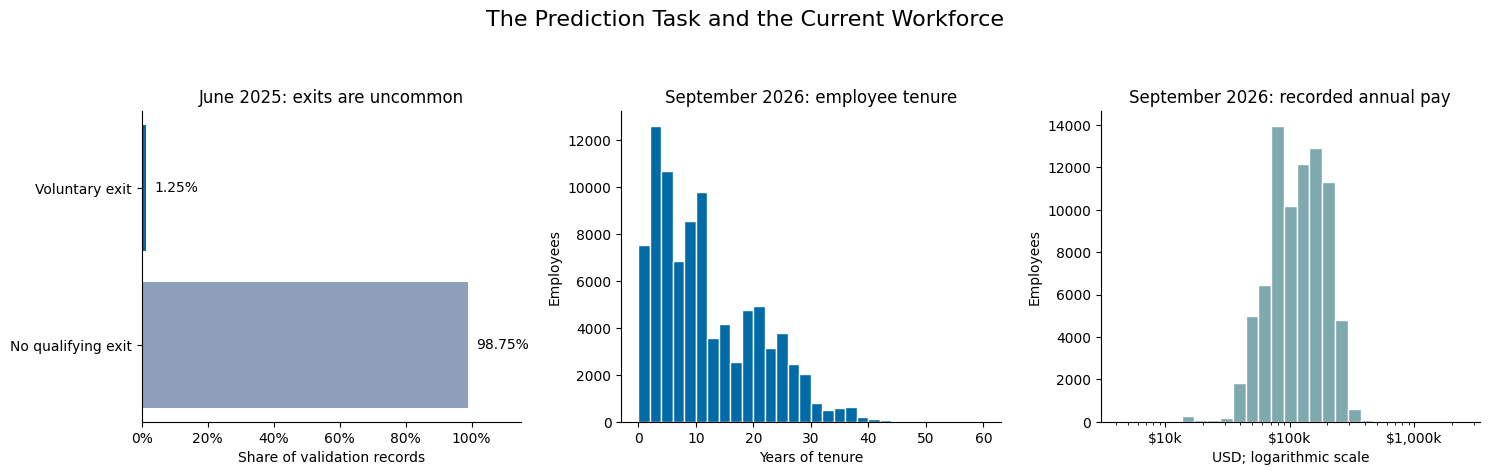

In [14]:
# Show exit frequency and current tenure and pay.
# Label each panel's population and period.
from matplotlib.ticker import FuncFormatter, PercentFormatter

validation_baseline = baseline_summary.loc[
    baseline_summary["data_period"] == "Validation"
].iloc[0]
validation_cases = int(validation_baseline["observed_attrition_cases"])
validation_records = int(validation_baseline["records"])
data_review_snapshot = df.loc[
    df["snapshot_date"] == df["snapshot_date"].max()
]
positive_rate = validation_cases / validation_records

data_overview_fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
axes[0].barh(["No qualifying exit", "Voluntary exit"], [1-positive_rate, positive_rate],
             color=["#8E9FBC", "#006BA6"])
axes[0].set_xlim(0, 1.15)
for i, value in enumerate([1-positive_rate, positive_rate]):
    axes[0].text(value+.025, i, f"{value:.2%}", va="center")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_xlabel("Share of validation records")
axes[0].set_title("June 2025: exits are uncommon")

tenure_years = data_review_snapshot["tenure_months"].dropna() / 12
axes[1].hist(tenure_years, bins=30, color="#006BA6", edgecolor="white")
axes[1].set_title("September 2026: employee tenure")
axes[1].set_xlabel("Years of tenure")
axes[1].set_ylabel("Employees")

salary = data_review_snapshot["annual_salary"].dropna()
salary = salary[salary > 0]
axes[2].hist(salary, bins=np.geomspace(salary.min(), salary.max(), 28),
             color="#7EA9AF", edgecolor="white")
axes[2].set_xscale("log")
axes[2].set_title("September 2026: recorded annual pay")
axes[2].set_xlabel("USD; logarithmic scale")
axes[2].set_ylabel("Employees")
axes[2].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1000:,.0f}k"))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
data_overview_fig.suptitle("The Prediction Task and the Current Workforce", fontsize=16)
data_overview_fig.tight_layout(rect=[0, 0, 1, .92])
plt.show()

## 6. Preparing Inputs Without Learning from Later Data

A **pipeline** keeps preparation and modeling repeatable. It fills numeric gaps with training medians, scales inputs where needed, and fills and encodes tested categories.

Each check learns these steps from training records, then applies them to later snapshots.

In [15]:
# Learn preparation from training, then reuse it.
def build_preprocess(num_feature_list, cat_feature_list=None):
    cat_feature_list = cat_feature_list or []

    transformers = [
        ("num", Pipeline([
            ("fill_missing", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_feature_list),
    ]

    if len(cat_feature_list) > 0:
        transformers.append((
            "cat",
            Pipeline([
                ("fill_missing", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
            ]),
            cat_feature_list,
        ))

    return ColumnTransformer(transformers)


num_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
])

full_preprocess = build_preprocess(num_features, cat_features)
numeric_only_preprocess = build_preprocess(num_features, [])

# Finalize preparation after testing categories.
preprocess = full_preprocess

print("Preprocessing builders ready.")
print("Numeric features:", num_features)
print("Candidate categorical features:", cat_features)

Preprocessing builders ready.
Numeric features: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']
Candidate categorical features: ['region', 'entity', 'service_area_new']


## 7. Deciding Which Inputs to Keep

I test inputs on two earlier calendar checks within training. I keep added complexity only when development AP improves enough, leaving June 2025 validation for the final model and cutoff choice.

### 7.1 Testing Choices on Two Earlier Forecast Dates

For each of two checks about six months apart, I train on records whose outcomes finish before the check date.

These checks choose inputs and **hyperparameters** (model settings), without using main validation or the holdout. They offer limited evidence about changing conditions.

In [16]:
from sklearn.preprocessing import MinMaxScaler


def build_fixed_snapshot_cv(
    snapshot_dates,
    outcome_window_months=6,
    snapshot_spacing_months=6,
    n_snapshots=2,
):
    """Create simple calendar checks using only completed earlier outcomes."""
    snapshot_dates = pd.Series(snapshot_dates).reset_index(drop=True)
    unique_dates = [
        pd.Timestamp(date)
        for date in sorted(snapshot_dates.dropna().unique())
    ]

    latest_snapshot = unique_dates[-1]
    validation_dates = []
    for offset in reversed(range(n_snapshots)):
        target_date = shift_month_end(
            latest_snapshot, -offset * snapshot_spacing_months
        )
        eligible_dates = [date for date in unique_dates if date <= target_date]
        if eligible_dates:
            validation_date = max(eligible_dates)
            if validation_date not in validation_dates:
                validation_dates.append(validation_date)

    folds = []
    summaries = []
    for validation_date in validation_dates:
        eligible_train_dates = [
            date
            for date in unique_dates
            if shift_month_end(date, outcome_window_months) < validation_date
        ]
        if not eligible_train_dates:
            continue

        train_idx = np.flatnonzero(
            snapshot_dates.isin(eligible_train_dates).to_numpy()
        )
        valid_idx = np.flatnonzero(
            (snapshot_dates == validation_date).to_numpy()
        )
        if len(train_idx) == 0 or len(valid_idx) == 0:
            continue

        train_end = max(eligible_train_dates)
        outcome_end = shift_month_end(train_end, outcome_window_months)
        if outcome_end >= validation_date:
            raise ValueError("A development check has overlapping outcome periods.")

        folds.append((train_idx, valid_idx))
        summaries.append({
            "validation_date": validation_date,
            "train_start": min(eligible_train_dates),
            "train_end": train_end,
            "train_outcome_end": outcome_end,
            "train_rows": len(train_idx),
            "validation_rows": len(valid_idx),
        })

    if len(folds) < 2:
        raise ValueError("At least two fixed calendar checks are required.")
    return folds, pd.DataFrame(summaries)


# Use the two available calendar checks.
temporal_cv, tuning_snapshot_summary = build_fixed_snapshot_cv(
    train_snapshot_dates,
    outcome_window_months=OUTCOME_WINDOW_MONTHS,
    snapshot_spacing_months=6,
    n_snapshots=2,
)

# Prepare training data for VIF and input ranking.
train_numeric = X_train[num_features].copy()
diagnostic_medians = train_numeric.median(numeric_only=True)
train_numeric_filled = train_numeric.fillna(diagnostic_medians)
minmax_scaler = MinMaxScaler(feature_range=(0, 1))
rescaled_train = pd.DataFrame(
    minmax_scaler.fit_transform(train_numeric_filled),
    columns=num_features,
    index=X_train.index,
)

print("Fixed training-period forecast checks:")
display(tuning_snapshot_summary)
print("Development checks available:", len(temporal_cv))
print("Outcome-window overlap check: PASSED")
print("Training numeric diagnostic matrix:", rescaled_train.shape)


Fixed training-period forecast checks:


,validation_date,train_start,train_end,train_outcome_end,train_rows,validation_rows
0,2024-05-31,2023-10-31,2023-10-31,2024-04-30,89706,90858
1,2024-11-30,2023-10-31,2024-04-30,2024-10-31,631039,91559


Development checks available: 2
Outcome-window overlap check: PASSED
Training numeric diagnostic matrix: (1272081, 13)


### 7.2 Testing Smaller Numeric Feature Sets

Chi-square scores on nonnegative scaled inputs suggest smaller lists to try. With these continuous inputs, I use the scores for screening and omit invalid categorical significance claims from the p-values.

I compare requested sets of 5, 8, 10 and all 13 inputs. Retained interactions keep their original inputs. Development AP decides which list stays.

In [17]:
from sklearn.feature_selection import SelectKBest, chi2


def preserve_interaction_hierarchy(feature_list):
    """Keep both original inputs when their interaction is retained."""
    selected = list(feature_list)
    if "compa_tenure_interaction" in selected:
        selected.extend(["compa_ratio", "tenure_months"])
    selected_set = set(selected)
    return [feature for feature in num_features if feature in selected_set]


# Learn preparation and input selection inside each check.
feature_selection_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("nonnegative_scale", MinMaxScaler(feature_range=(0, 1))),
    ("selector", SelectKBest(score_func=chi2)),
    ("clf", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        class_weight={0: 1, 1: 5},
        random_state=RANDOM_STATE,
    )),
])

requested_k_values = [5, 8, 10, len(num_features)]
feature_k_search = GridSearchCV(
    feature_selection_pipeline,
    param_grid={"selector__k": requested_k_values},
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    return_train_score=True,
)
feature_k_search.fit(X_train[num_features], y_train)

feature_k_results = pd.DataFrame(feature_k_search.cv_results_)
feature_k_search_df = pd.DataFrame({
    "requested_k": feature_k_results["param_selector__k"].astype(int),
    "cv_train_average_precision": feature_k_results["mean_train_score"],
    "cv_average_precision": feature_k_results["mean_test_score"],
    "cv_average_precision_std": feature_k_results["std_test_score"],
    "rank": feature_k_results["rank_test_score"].astype(int),
}).sort_values("rank").reset_index(drop=True)

best_k = int(feature_k_search.best_params_["selector__k"])
selected_mask = feature_k_search.best_estimator_.named_steps[
    "selector"
].get_support()
automated_features = [
    feature for feature, keep in zip(num_features, selected_mask) if keep
]
automated_features = preserve_interaction_hierarchy(automated_features)

# Rank inputs using training data only.
chi2_selector = SelectKBest(score_func=chi2, k="all")
chi2_selector.fit(rescaled_train, y_train)
feature_scores = (
    pd.DataFrame({
        "feature": num_features,
        "chi2_score": chi2_selector.scores_,
        "p_value": chi2_selector.pvalues_,
    })
    .sort_values("chi2_score", ascending=False)
    .reset_index(drop=True)
)


def evaluate_numeric_feature_set(feature_set_name, feature_list):
    """Measure one concrete feature list across the training-period checks."""
    feature_list = list(feature_list)
    reference_pipeline = Pipeline([
        ("preprocess", build_preprocess(feature_list, [])),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight={0: 1, 1: 5},
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_validate(
        reference_pipeline,
        X_train[feature_list],
        y_train,
        scoring="average_precision",
        cv=temporal_cv,
        n_jobs=1,
        return_train_score=True,
    )
    mean_train_ap = float(np.mean(scores["train_score"]))
    mean_check_ap = float(np.mean(scores["test_score"]))
    return {
        "feature_set": feature_set_name,
        "feature_count": len(feature_list),
        "features": feature_list,
        "cv_train_average_precision": mean_train_ap,
        "development_average_precision": mean_check_ap,
        "development_ap_std": float(np.std(scores["test_score"])),
        "overfit_gap": mean_train_ap - mean_check_ap,
    }


feature_selection_rows = [
    evaluate_numeric_feature_set(
        f"Automated top {best_k} with hierarchy",
        automated_features,
    )
]
if automated_features != num_features:
    feature_selection_rows.append(
        evaluate_numeric_feature_set("All numeric candidates", num_features)
    )

feature_selection_comparison_df = (
    pd.DataFrame(feature_selection_rows)
    .sort_values("development_average_precision", ascending=False)
    .reset_index(drop=True)
)

all_numeric_matches = feature_selection_comparison_df.loc[
    feature_selection_comparison_df["feature_set"] == "All numeric candidates"
]
if all_numeric_matches.empty:
    all_numeric_row = feature_selection_comparison_df.iloc[0]
else:
    all_numeric_row = all_numeric_matches.iloc[0]
best_numeric_row = feature_selection_comparison_df.iloc[0]

minimum_numeric_ap_gain = 0.001
numeric_subset_ap_gain = (
    best_numeric_row["development_average_precision"]
    - all_numeric_row["development_average_precision"]
)

if (
    best_numeric_row["feature_set"] != "All numeric candidates"
    and numeric_subset_ap_gain >= minimum_numeric_ap_gain
):
    signal_selected_num_features = list(best_numeric_row["features"])
    signal_selection_reason = (
        f"retained {best_numeric_row['feature_set']} because mean development AP "
        f"improved by {numeric_subset_ap_gain:.4f}"
    )
else:
    signal_selected_num_features = num_features.copy()
    signal_selection_reason = (
        "retained all numeric candidates because the concrete subset did not "
        f"improve mean development AP by at least {minimum_numeric_ap_gain:.4f}"
    )

print("Automated feature-count search using training-period checks:")
display(feature_k_search_df.round(5))
print("Training-only chi-square ranking:")
display(feature_scores.drop(columns="p_value"))
print("Concrete feature-list confirmation:")
display(feature_selection_comparison_df.drop(columns="features").round(5))
print("Feature decision:", signal_selection_reason)
print("Features after signal check:", signal_selected_num_features)


Automated feature-count search using training-period checks:


,requested_k,cv_train_average_precision,cv_average_precision,cv_average_precision_std,rank
0,13,0.05931,0.03681,0.00500,1
1,8,0.06015,0.03645,0.00408,2
2,10,0.06010,0.03630,0.00392,3
3,5,0.05756,0.03619,0.00504,4


Training-only chi-square ranking:


,feature,chi2_score
0,tenure_months,927.295888
1,underpaid_flag,709.061780
2,low_performer,398.515337
3,high_mgr_attrition,376.546719
4,compa_tenure_interaction,304.200602
5,mgr_attrition_6mo_rate,156.691318
6,mgr_attrition_12mo_rate,150.695209
7,mgr_avg_team_tenure,102.275872
8,performance_rating,32.024418
9,mgr_low_perf_pct,12.610794


Concrete feature-list confirmation:


,feature_set,feature_count,cv_train_average_precision,development_average_precision,development_ap_std,overfit_gap
0,Automated top 13 with hierarchy,13,0.06172,0.03896,0.00556,0.02276


Feature decision: retained all numeric candidates because the concrete subset did not improve mean development AP by at least 0.0010
Features after signal check: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']


The search keeps **all 13 numeric inputs**. Smaller sets miss the required gain of 0.001 AP (0.1 percentage point).

### 7.3 Checking Whether Inputs Overlap Too Much

**Variance inflation factor (VIF)** flags linear overlap that can complicate coefficient interpretation. Removing the proposed inputs does not improve development AP enough, so I keep them. Read their weights together, especially the pay–tenure interaction.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Keep VIF repeatable with a fixed training sample.
vif_sample = rescaled_train[signal_selected_num_features].sample(
    n=min(200_000, len(rescaled_train)),
    random_state=RANDOM_STATE,
)
vif_with_intercept = np.column_stack([
    np.ones(len(vif_sample)),
    vif_sample.to_numpy(),
])

vif_data = pd.DataFrame({
    "feature": signal_selected_num_features,
    "vif": [
        variance_inflation_factor(vif_with_intercept, index + 1)
        for index in range(len(signal_selected_num_features))
    ],
}).sort_values("vif", ascending=False).reset_index(drop=True)

signal_feature_key = tuple(signal_selected_num_features)
signal_development_row = feature_selection_comparison_df.loc[
    feature_selection_comparison_df["features"].map(tuple) == signal_feature_key
].iloc[0]
signal_development_ap = signal_development_row["development_average_precision"]

vif_validation_rows = [{
    "feature_set": "Signal-selected baseline",
    "removed_feature": None,
    "feature_count": len(signal_selected_num_features),
    "development_average_precision": signal_development_ap,
    "features": signal_selected_num_features,
}]

high_vif_features = vif_data.loc[vif_data["vif"] > 10, "feature"].tolist()
protected_main_effects = {"compa_ratio", "tenure_months"}
removal_candidates = [
    feature for feature in high_vif_features
    if feature not in protected_main_effects
]

if (
    "compa_tenure_interaction" in signal_selected_num_features
    and vif_data["vif"].max() > 10
    and "compa_tenure_interaction" not in removal_candidates
):
    removal_candidates.append("compa_tenure_interaction")

for feature_to_remove in removal_candidates[:3]:
    reduced_features = [
        feature for feature in signal_selected_num_features
        if feature != feature_to_remove
    ]
    reduced_result = evaluate_numeric_feature_set(
        f"Remove {feature_to_remove}",
        reduced_features,
    )
    vif_validation_rows.append({
        "feature_set": reduced_result["feature_set"],
        "removed_feature": feature_to_remove,
        "feature_count": reduced_result["feature_count"],
        "development_average_precision": reduced_result[
            "development_average_precision"
        ],
        "features": reduced_features,
    })

vif_validation_df = (
    pd.DataFrame(vif_validation_rows)
    .sort_values("development_average_precision", ascending=False)
    .reset_index(drop=True)
)

best_vif_row = vif_validation_df.iloc[0]
minimum_vif_ap_gain = 0.001
vif_ap_gain = (
    best_vif_row["development_average_precision"] - signal_development_ap
)

if (
    best_vif_row["feature_set"] != "Signal-selected baseline"
    and vif_ap_gain >= minimum_vif_ap_gain
):
    selected_num_features = list(best_vif_row["features"])
    overlap_selection_reason = (
        f"removed {best_vif_row['removed_feature']} because mean development AP "
        f"improved by {vif_ap_gain:.4f}"
    )
else:
    selected_num_features = signal_selected_num_features.copy()
    overlap_selection_reason = (
        "retained the signal-selected features because no VIF-triggered removal "
        f"improved mean development AP by at least {minimum_vif_ap_gain:.4f}"
    )

numeric_feature_set_name = (
    "All candidate numeric features"
    if selected_num_features == num_features
    else "Training-validated numeric subset"
)

print("Training-sample VIF diagnostic:")
display(vif_data.round(3))
print("Training-period check for VIF-triggered removals:")
display(vif_validation_df.drop(columns="features").round(5))
print("Overlap decision:", overlap_selection_reason)
print("Numeric features carried forward:", selected_num_features)


Training-sample VIF diagnostic:


,feature,vif
0,compa_tenure_interaction,51.593
1,tenure_months,48.901
2,compa_ratio,2.283
3,mgr_attrition_12mo_rate,1.920
4,underpaid_flag,1.876
5,high_mgr_attrition,1.780
6,mgr_avg_team_tenure,1.277
7,mgr_attrition_6mo_rate,1.250
8,mgr_team_size,1.118
9,performance_rating,1.116


Training-period check for VIF-triggered removals:


,feature_set,removed_feature,feature_count,development_average_precision
0,Signal-selected baseline,None,13,0.03896
1,Remove compa_tenure_interaction,compa_tenure_interaction,12,0.03311


Overlap decision: retained the signal-selected features because no VIF-triggered removal improved mean development AP by at least 0.0010
Numeric features carried forward: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']


### 7.4 Identifying Whether Organization Categories Add Value

Adding region, entity and service area changes mean development AP by **-0.03 percentage point**, below the required 0.1-point gain. I leave them out as predictors, while keeping their context for reviewing results.

In [19]:
selected_numeric_preprocess = build_preprocess(selected_num_features, [])
selected_with_categories = selected_num_features + cat_features
selected_full_preprocess = build_preprocess(selected_num_features, cat_features)

cat_development_configs = [
    ("Selected numeric", selected_num_features, selected_numeric_preprocess),
    (
        "Selected numeric + categorical",
        selected_with_categories,
        selected_full_preprocess,
    ),
]

cat_development_results = []
for name, feature_set, transformer in cat_development_configs:
    diagnostic_pipeline = Pipeline([
        ("preprocess", transformer),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight={0: 1, 1: 5},
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_validate(
        diagnostic_pipeline,
        X_train[feature_set],
        y_train,
        scoring="average_precision",
        cv=temporal_cv,
        n_jobs=1,
        return_train_score=True,
    )
    mean_train_ap = float(np.mean(scores["train_score"]))
    mean_check_ap = float(np.mean(scores["test_score"]))
    cat_development_results.append({
        "feature_set": name,
        "feature_count": len(feature_set),
        "cv_train_average_precision": mean_train_ap,
        "cv_average_precision": mean_check_ap,
        "cv_average_precision_std": float(np.std(scores["test_score"])),
        "overfit_gap": mean_train_ap - mean_check_ap,
    })

# Keep the output name; decide using development checks.
cat_validation_df = pd.DataFrame(cat_development_results)
display(cat_validation_df.round(5))

numeric_ap = cat_validation_df.loc[
    cat_validation_df["feature_set"] == "Selected numeric",
    "cv_average_precision",
].iloc[0]
full_ap = cat_validation_df.loc[
    cat_validation_df["feature_set"] == "Selected numeric + categorical",
    "cv_average_precision",
].iloc[0]

categorical_ap_gain = full_ap - numeric_ap
minimum_categorical_ap_gain = 0.001
categorical_features_improve = categorical_ap_gain >= minimum_categorical_ap_gain

final_num_features = selected_num_features.copy()
if categorical_features_improve:
    final_cat_features = cat_features.copy()
    final_feature_set_name = numeric_feature_set_name + " + categorical"
else:
    final_cat_features = []
    final_feature_set_name = numeric_feature_set_name

final_model_features = final_num_features + final_cat_features
final_preprocess = build_preprocess(final_num_features, final_cat_features)

# Give every model the same inputs.
selected_model_features = final_model_features
selected_preprocess = final_preprocess
preprocess = final_preprocess

print(f"Development AP gain from categorical features: {categorical_ap_gain:.4f}")
print(f"Minimum AP gain required: {minimum_categorical_ap_gain:.4f}")
if categorical_features_improve:
    print("Decision: retain categorical features in the final modeling pipeline.")
else:
    print(
        "Decision: exclude categorical features because the development AP gain "
        "did not justify the added complexity."
    )
print("Final feature set:", final_feature_set_name)
print("Final model features:", final_model_features)


,feature_set,feature_count,cv_train_average_precision,cv_average_precision,cv_average_precision_std,overfit_gap
0,Selected numeric,13,0.06172,0.03896,0.00556,0.02276
1,Selected numeric + categorical,16,0.06344,0.03865,0.00574,0.02478


Development AP gain from categorical features: -0.0003
Minimum AP gain required: 0.0010
Decision: exclude categorical features because the development AP gain did not justify the added complexity.
Final feature set: All candidate numeric features
Final model features: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']


### 7.5 Using the Same Inputs for Each Model

All three models use the same **13 numeric inputs and 0 categorical inputs**, selected within training. The table shows the final list.

In [20]:
# Show the final input list.
feature_summary = pd.DataFrame({
    "feature": final_model_features,
    "type": ["numeric"] * len(final_num_features) + ["categorical"] * len(final_cat_features),
})

print(f"Number of numeric features: {len(final_num_features)}")
print(f"Number of categorical features retained: {len(final_cat_features)}")
print(f"Total final model features: {len(final_model_features)}")
print("Final feature set decision:", final_feature_set_name)

display(feature_summary)

missing_features = [col for col in final_model_features if col not in X_train.columns]
if missing_features:
    raise ValueError(f"Missing final features: {missing_features}")
else:
    print("All final features are present in train, validation, and test matrices.")

Number of numeric features: 13
Number of categorical features retained: 0
Total final model features: 13
Final feature set decision: All candidate numeric features


,feature,type
0,annual_salary,numeric
1,compa_ratio,numeric
2,performance_rating,numeric
3,tenure_months,numeric
4,low_performer,numeric
5,mgr_team_size,numeric
6,mgr_avg_team_tenure,numeric
7,mgr_low_perf_pct,numeric
8,mgr_attrition_6mo_rate,numeric
9,mgr_attrition_12mo_rate,numeric


All final features are present in train, validation, and test matrices.


## 8. Starting with Logistic Regression

Logistic Regression combines inputs into a weighted score. I use it as an interpretable benchmark and test **regularization** to limit overly large weights.

Class weighting emphasizes exit cases; under-sampling reduces no-exit records during training. I compare these choices and L1/L2 penalties using development AP. Evaluation keeps the real outcome balance.

In [21]:
from sklearn.exceptions import ConvergenceWarning

# Check convergence for all fits.
# Stop if convergence fails.
lr_convergence_records = []


class ConvergenceCheckedLogisticRegression(LogisticRegression):
    def fit(self, X, y, sample_weight=None):
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            super().fit(X, y, sample_weight=sample_weight)
        convergence_warnings = [
            item for item in fit_warnings
            if issubclass(item.category, ConvergenceWarning)
        ]
        iterations = int(np.max(self.n_iter_))
        lr_convergence_records.append({
            "training_rows": len(y), "C": self.C, "penalty": self.penalty,
            "solver": self.solver,
            "class_weight": str(self.class_weight), "iterations": iterations,
            "iteration_limit": self.max_iter,
            "converged": not convergence_warnings and iterations < self.max_iter,
        })
        for item in fit_warnings:
            if not issubclass(item.category, ConvergenceWarning):
                warnings.warn(str(item.message), item.category)
        if convergence_warnings or iterations >= self.max_iter:
            raise RuntimeError(
                "Logistic Regression did not converge; increase the iteration "
                "budget and rerun development checks before comparing models."
            )
        return self


from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler


# Sample during fitting only; keep evaluation unchanged.
lr_pipeline = ImbPipeline([
    ("preprocess", final_preprocess),
    ("sampler", "passthrough"),
    ("clf", ConvergenceCheckedLogisticRegression(
        solver="saga",
        max_iter=5000,
        tol=1e-3,
        random_state=RANDOM_STATE,
    )),
])

# Try a small set of weighting and regularization choices.
lr_param_grid = []
for class_weight in [{0: 1, 1: 3}, {0: 1, 1: 5}, "balanced"]:
    for c_value in [0.1, 1.0]:
        lr_param_grid.append({
            "sampler": ["passthrough"],
            "clf__class_weight": [class_weight],
            # The earlier balanced SAGA fit hit 5,000 iterations.
            # Use LBFGS for those L2 candidates.
            "clf__solver": ["lbfgs" if class_weight == "balanced" else "saga"],
            "clf__C": [c_value],
            "clf__penalty": ["l2"],
        })

for c_value in [0.01, 10.0]:
    lr_param_grid.append({
        "sampler": ["passthrough"],
        "clf__class_weight": [{0: 1, 1: 5}],
        "clf__C": [c_value],
        "clf__penalty": ["l2"],
    })

for c_value in [0.1, 1.0]:
    lr_param_grid.append({
        "sampler": ["passthrough"],
        "clf__class_weight": [{0: 1, 1: 5}],
        "clf__C": [c_value],
        "clf__penalty": ["l1"],
    })

for sampling_ratio in [0.05, 0.10, 0.20]:
    lr_param_grid.append({
        "sampler": [RandomUnderSampler(
            sampling_strategy=sampling_ratio,
            random_state=RANDOM_STATE,
        )],
        "clf__class_weight": [None],
        "clf__C": [1.0],
        "clf__penalty": ["l2"],
    })

lr_param_grid.append({
    "sampler": [RandomUnderSampler(
        sampling_strategy=0.10,
        random_state=RANDOM_STATE,
    )],
    "clf__class_weight": [None],
    "clf__C": [0.1],
    "clf__penalty": ["l2"],
})

lr_search = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    verbose=1,
    return_train_score=True,
    error_score="raise",
)
lr_search.fit(X_train[final_model_features], y_train)

lr_model = lr_search.best_estimator_
lr_model_features = final_model_features


def describe_sampler(value):
    if value == "passthrough":
        return "No resampling"
    ratio = float(value.sampling_strategy)
    return f"Random under-sampling (1:{1 / ratio:.0f})"


def describe_class_weight(value):
    if value is None:
        return "None"
    if value == "balanced":
        return "Balanced"
    return f"{value[1]:g}:1"


lr_cv_results = pd.DataFrame(lr_search.cv_results_)
lr_imbalance_comparison_df = pd.DataFrame({
    "imbalance_strategy": lr_cv_results["param_sampler"].map(describe_sampler),
    "class_weight": lr_cv_results["param_clf__class_weight"].map(
        describe_class_weight
    ),
    "C": lr_cv_results["param_clf__C"].astype(float),
    "penalty": lr_cv_results["param_clf__penalty"].astype(str),
    "solver": lr_cv_results["params"].map(lambda p: p.get("clf__solver", "saga")),
    "cv_train_average_precision": lr_cv_results["mean_train_score"],
    "cv_average_precision": lr_cv_results["mean_test_score"],
    "cv_overfit_gap": (
        lr_cv_results["mean_train_score"] - lr_cv_results["mean_test_score"]
    ),
    "cv_average_precision_std": lr_cv_results["std_test_score"],
    "rank": lr_cv_results["rank_test_score"].astype(int),
}).sort_values(["rank", "imbalance_strategy", "C", "penalty"]).reset_index(drop=True)

baseline_mask = (
    (lr_imbalance_comparison_df["imbalance_strategy"] == "No resampling")
    & (lr_imbalance_comparison_df["class_weight"] == "5:1")
    & (lr_imbalance_comparison_df["C"] == 1.0)
    & (lr_imbalance_comparison_df["penalty"] == "l2")
)
baseline_ap = lr_imbalance_comparison_df.loc[
    baseline_mask, "cv_average_precision"
].iloc[0]
imbalance_tuning_ap_gain = lr_search.best_score_ - baseline_ap

best_sampler = describe_sampler(lr_search.best_params_["sampler"])
best_class_weight = describe_class_weight(
    lr_search.best_params_["clf__class_weight"]
)
lr_cv_train_ap = float(
    lr_search.cv_results_["mean_train_score"][lr_search.best_index_]
)
lr_cv_validation_ap = float(lr_search.best_score_)
lr_cv_overfit_gap = lr_cv_train_ap - lr_cv_validation_ap

display(lr_imbalance_comparison_df.round(5))
print("Logistic Regression feature set:", final_feature_set_name)
print("Selected imbalance strategy:", best_sampler)
print("Selected class weight:", best_class_weight)
print("Selected C:", lr_search.best_params_["clf__C"])
print("Selected penalty:", lr_search.best_params_["clf__penalty"])
print("Best development average precision:", round(lr_search.best_score_, 6))
print("Reference 5:1, C=1.0, L2 average precision:", round(baseline_ap, 6))
print("Average-precision gain from tuning:", round(imbalance_tuning_ap_gain, 6))
print("Selected training average precision:", round(lr_cv_train_ap, 6))
print("Selected overfitting gap:", round(lr_cv_overfit_gap, 6))


lr_convergence_audit = pd.DataFrame(lr_convergence_records)
if not lr_convergence_audit["converged"].all():
    raise RuntimeError("Not all Logistic Regression fits passed convergence verification.")
print("Convergence verified for candidate-fold and selected refit:", len(lr_convergence_audit), "fits")
print("Largest iteration count:", int(lr_convergence_audit["iterations"].max()))
print("Iteration budget:", lr_model.named_steps["clf"].max_iter)
print("Selected full-training iterations:", int(np.max(lr_model.named_steps["clf"].n_iter_)))

print("Selected solver:", lr_model.named_steps["clf"].solver)

print("Convergence audit by solver and penalty:")
display(lr_convergence_audit.groupby(["solver", "penalty"]).agg(
    fits=("converged", "size"),
    max_iterations=("iterations", "max"),
    all_converged=("converged", "all"),
))


Fitting 2 folds for each of 14 candidates, totalling 28 fits


,imbalance_strategy,class_weight,C,penalty,solver,cv_train_average_precision,cv_average_precision,cv_overfit_gap,cv_average_precision_std,rank
0,Random under-sampling (1:5),None,1.00,l2,saga,0.06113,0.03960,0.02153,0.00636,1
1,Random under-sampling (1:10),None,1.00,l2,saga,0.06129,0.03914,0.02215,0.00618,2
2,No resampling,5:1,10.00,l2,saga,0.06172,0.03896,0.02276,0.00555,3
3,No resampling,5:1,1.00,l1,saga,0.06171,0.03894,0.02278,0.00556,4
4,No resampling,5:1,1.00,l2,saga,0.06173,0.03893,0.02280,0.00556,5
5,No resampling,3:1,1.00,l2,saga,0.06202,0.03892,0.02310,0.00557,6
6,No resampling,5:1,0.10,l1,saga,0.06174,0.03882,0.02292,0.00544,7
7,No resampling,5:1,0.10,l2,saga,0.06165,0.03875,0.02290,0.00541,8
8,No resampling,3:1,0.10,l2,saga,0.06185,0.03869,0.02316,0.00532,9
9,Random under-sampling (1:20),None,1.00,l2,saga,0.06180,0.03863,0.02317,0.00549,10


Logistic Regression feature set: All candidate numeric features
Selected imbalance strategy: Random under-sampling (1:5)
Selected class weight: None
Selected C: 1.0
Selected penalty: l2
Best development average precision: 0.0396
Reference 5:1, C=1.0, L2 average precision: 0.038934
Average-precision gain from tuning: 0.000666
Selected training average precision: 0.061128
Selected overfitting gap: 0.021528
Convergence verified for candidate-fold and selected refit: 29 fits
Largest iteration count: 154
Iteration budget: 5000
Selected full-training iterations: 32
Selected solver: saga
Convergence audit by solver and penalty:


fits  max_iterations  all_converged
solver penalty                                     
lbfgs  l2          4              15           True
saga   l1          4              46           True
       l2         21             154           True

The search selects **random under-sampling at 1:5**, no class weighting, `C=1` and L2 regularization. Sampling changes training only; evaluation keeps the real outcome balance.

Development AP is **3.96%**, with a **2.15-percentage-point** gap. The gain over the 5:1-weighted, `C=1`, L2 reference is **0.0666 percentage point**, a modest improvement.

### Checking That the Fitting Process Finished Properly

The selected model uses SAGA. Balanced-weight L2 candidates use LBFGS after an earlier iteration-limit warning. All **29 fits** pass convergence checks. The maximum is **154 iterations**, and the selected full-training fit uses **32**, within the 5,000-iteration budget. Convergence does not establish usefulness.

## 9. Turning a Ranking into an HR Review List

I choose the highest validation cutoff that captures at least **25% of observed voluntary-exit cases**. This gives a focused list for comparing models.

HR has not agreed that this workload is practical. The table shows how it changes when we ask to find fewer or more cases.

In [22]:
# Find a focused list with at least 25% validation recall.
def choose_threshold_for_recall(y_true, y_prob, target_recall=0.25):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    threshold_rows = pd.DataFrame({
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1],
    })
    threshold_rows["f1"] = (
        2 * threshold_rows["precision"] * threshold_rows["recall"] /
        (threshold_rows["precision"] + threshold_rows["recall"] + 1e-12)
    )
    threshold_rows["flagged_rate"] = [
        np.mean(y_prob >= threshold)
        for threshold in threshold_rows["threshold"]
    ]

    eligible = threshold_rows.loc[
        threshold_rows["recall"] >= target_recall
    ].copy()
    if len(eligible) > 0:
        chosen = eligible.sort_values("threshold", ascending=False).iloc[0]
        decision = "target_recall_met"
    else:
        chosen = threshold_rows.sort_values("f1", ascending=False).iloc[0]
        decision = "fallback_best_f1"

    return float(chosen["threshold"]), chosen.to_dict(), threshold_rows, decision


def evaluate_at_threshold(model_name, y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    ap = average_precision_score(y_true, y_prob)
    base_rate = float(np.mean(y_true))
    precision_value = precision_score(y_true, y_pred, zero_division=0)
    recall_value = recall_score(y_true, y_pred, zero_division=0)

    return {
        "model": model_name,
        "threshold": threshold,
        "average_precision": ap,
        "roc_auc": roc_auc_score(y_true, y_prob),
        "base_rate": base_rate,
        "lift_vs_base": precision_value / base_rate if base_rate > 0 else np.nan,
        "precision": precision_value,
        "recall": recall_value,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "flagged_rate": float(np.mean(y_pred)),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }, y_pred


target_recall = 0.25

# Choose the cutoff on validation only.
lr_valid_prob = lr_model.predict_proba(X_valid[lr_model_features])[:, 1]
lr_threshold, lr_threshold_info, lr_threshold_table, lr_threshold_policy = (
    choose_threshold_for_recall(
        y_valid,
        lr_valid_prob,
        target_recall=target_recall,
    )
)
lr_valid_metrics, lr_valid_pred = evaluate_at_threshold(
    "Logistic Regression",
    y_valid,
    lr_valid_prob,
    lr_threshold,
)

print("Target recall:", target_recall)
print("Logistic Regression threshold decision:", lr_threshold_policy)
print("Chosen Logistic Regression threshold:", lr_threshold)
print("Validation threshold details:")
display(pd.DataFrame([lr_threshold_info]).round(4))


Target recall: 0.25
Logistic Regression threshold decision: target_recall_met
Chosen Logistic Regression threshold: 0.277027845129052
Validation threshold details:


,threshold,precision,recall,f1,flagged_rate
0,0.277,0.0359,0.2504,0.0628,0.0874


### 9.1 Connecting Cases Captured to Review Capacity

At the 25% target, Logistic Regression finds **286 of 1,142 cases** with **7,964 reviews** (8.7% of employees) and **3.59% precision**. HR still needs to agree what workload and supportive follow-up are practical.

In [23]:
# Compare workload at three recall targets.
capacity_targets = [0.10, target_recall, 0.50]
capacity_rows = []

for capacity_target in capacity_targets:
    threshold, details, _, _ = choose_threshold_for_recall(
        y_valid,
        lr_valid_prob,
        target_recall=capacity_target,
    )
    capacity_pred = lr_valid_prob >= threshold
    capacity_rows.append({
        "Recall target": f"{capacity_target:.0%}",
        "Validation cases captured": f"{int(((y_valid.to_numpy() == 1) & capacity_pred).sum()):,}",
        "Approx. employees flagged": f"{int(round(capacity_pred.sum(), -2)):,}",
        "Workforce flagged": f"{capacity_pred.mean():.1%}",
        "Precision": f"{details['precision']:.1%}",
    })

# Show the workload needed to find more cases.
validation_capacity_comparison = pd.DataFrame(capacity_rows)
display(validation_capacity_comparison)

,Recall target,Validation cases captured,Approx. employees flagged,Workforce flagged,Precision
0,10%,115,"3,200",3.5%,3.6%
1,25%,286,"8,000",8.7%,3.6%
2,50%,571,"21,500",23.6%,2.7%


## 10. Checking Logistic Regression on Validation

I check Logistic Regression on June 2025 after choosing inputs and settings. Curves show results across cutoffs; the confusion matrix counts outcomes at the selected cutoff.

The January historical check follows final model selection.

In [24]:
# Check validation before replaying the holdout.
print("Logistic Regression validation metrics:")
display(pd.DataFrame([lr_valid_metrics]).round(4))

print("Logistic Regression classification report on validation:")
print(classification_report(y_valid, lr_valid_pred, zero_division=0))


Logistic Regression validation metrics:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Logistic Regression,0.277,0.0267,0.7015,0.0125,2.8669,0.0359,0.2504,0.0628,0.0874,286,7678,856,82347


Logistic Regression classification report on validation:
              precision    recall  f1-score   support

         0.0       0.99      0.91      0.95     90025
         1.0       0.04      0.25      0.06      1142

    accuracy                           0.91     91167
   macro avg       0.51      0.58      0.51     91167
weighted avg       0.98      0.91      0.94     91167



Logistic Regression finds **25.0%** of validation cases with **3.59% precision** and **8.7%** listed. AP is **2.67%**, versus the **1.25%** untargeted reference. The list has **2.9 times** the workforce exit concentration; most exit cases remain outside it.

### 10.2 Looking at Separation Across Cutoffs

The **ROC curve** shows how capturing more exit cases also brings more no-exit records above the cutoff. ROC-AUC summarizes that separation: 0.5 is random ranking and 1.0 is perfect separation. I include it as a second view of ranking quality, alongside AP and the review-list measures.

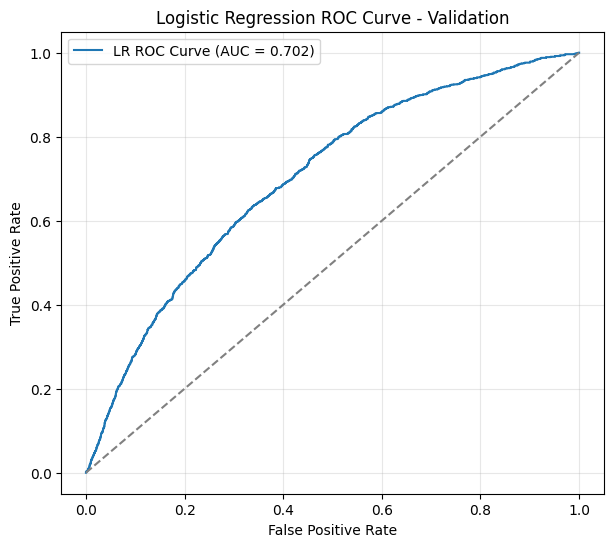

In [25]:
# Plot ROC performance: 0.5 is random; 1.0 is perfect.
fpr, tpr, _ = roc_curve(y_valid, lr_valid_prob)
lr_valid_roc_auc = roc_auc_score(y_valid, lr_valid_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"LR ROC Curve (AUC = {lr_valid_roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve - Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 10.3 Looking at the Tradeoff HR Would Face

The **precision-recall curve** shows how the list's exit share changes as more cases are captured. The horizontal line is the untargeted reference; the marked point is the validation cutoff. It helps explain the tradeoff HR would face.

In [26]:
# Show precision as more exit cases are captured.
import plotly.graph_objects as go

lr_precision_curve, lr_recall_curve, _ = precision_recall_curve(
    y_valid, lr_valid_prob
)
lr_valid_ap = average_precision_score(y_valid, lr_valid_prob)
lr_validation_baseline = y_valid.mean()

lr_pr_fig = go.Figure()
lr_pr_fig.add_trace(go.Scatter(
    x=lr_recall_curve,
    y=lr_precision_curve,
    mode="lines",
    name=f"LR PR Curve (AP = {lr_valid_ap:.2%})",
    line=dict(color="#1f77b4", width=2),
    hovertemplate="Recall: %{x:.2%}<br>Precision: %{y:.2%}<extra>Logistic Regression</extra>",
))
lr_pr_fig.add_trace(go.Scatter(
    x=[0, 1],
    y=[lr_validation_baseline, lr_validation_baseline],
    mode="lines",
    name=f"Baseline = {lr_validation_baseline:.2%}",
    line=dict(color="#7f7f7f", dash="dash", width=2),
    hovertemplate="Workforce exit rate: %{y:.2%}<extra>Untargeted baseline</extra>",
))
lr_pr_fig.add_trace(go.Scatter(
    x=[lr_valid_metrics["recall"]],
    y=[lr_valid_metrics["precision"]],
    mode="markers",
    name="Selected LR threshold",
    marker=dict(color="#CB333B", size=11),
    customdata=[[lr_valid_metrics["threshold"], lr_valid_metrics["flagged_rate"]]],
    hovertemplate=(
        "Recall: %{x:.2%}<br>Precision: %{y:.2%}"
        "<br>LR cutoff: %{customdata[0]:.3f}"
        "<br>Workforce flagged: %{customdata[1]:.2%}<extra>Selected LR threshold</extra>"
    ),
))
lr_pr_fig.update_layout(
    title=dict(text="Logistic Regression Precision-Recall Curve<br>Validation",
               x=0.5, y=0.98, xanchor="center", yanchor="top", font=dict(size=19)),
    template="plotly_white",
    width=950,
    height=690,
    font=dict(size=13),
    margin=dict(l=90, r=45, t=100, b=155),
    # Keep the legend clear of the title.
    legend=dict(orientation="h", x=0, y=-0.20, xanchor="left",
                yanchor="top", font=dict(size=12)),
    hovermode="closest",
    xaxis=dict(title="Recall", tickformat=".0%", range=[0, 1], gridcolor="#eeeeee",
               automargin=True, title_standoff=18, ticks="outside", ticklen=5),
    yaxis=dict(title="Precision", tickformat=".0%", range=[0, 1.05], gridcolor="#eeeeee",
               automargin=True, title_standoff=18, ticks="outside", ticklen=5),
)
lr_pr_fig.show()


### 10.4 Counting What the List Finds and Misses

The **confusion matrix** counts exit and no-exit records inside and outside the list: true positives, false positives, false negatives and true negatives.

For HR, it shows cases found, additional reviews and cases missed. “No exit” means no qualifying voluntary exit within the target window.

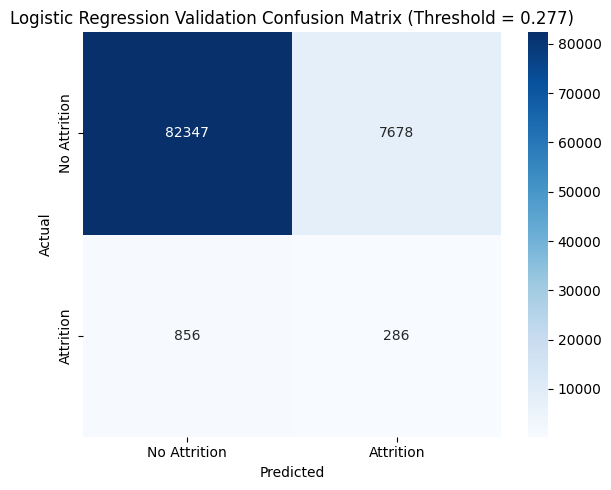

In [27]:
# Count cases found, cases missed and other reviews.
cm = confusion_matrix(y_valid, lr_valid_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    f"Logistic Regression Validation Confusion Matrix "
    f"(Threshold = {lr_threshold:.3f})"
)
plt.tight_layout()
plt.show()


## 11. Testing a More Flexible Alternative: Random Forest

Random Forest combines trees to capture patterns a linear score may miss. I compare a flexible reference with shallower trees and larger leaves.

My **overfitting safeguard** limits training AP to no more than **five percentage points** above development AP. If none passes, I keep the smallest-gap candidate for comparison and flag its limitation. Passing does not guarantee future performance.

In [28]:
# Start with a flexible forest for comparison.
rf_reference_pipeline = Pipeline([
    ("preprocess", final_preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=20,
        min_samples_split=10,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_reference_scores = cross_validate(
    rf_reference_pipeline,
    X_train[final_model_features],
    y_train,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    return_train_score=True,
)
rf_reference_train_ap = float(np.mean(rf_reference_scores["train_score"]))
rf_reference_validation_ap = float(np.mean(rf_reference_scores["test_score"]))
rf_reference_gap = rf_reference_train_ap - rf_reference_validation_ap

# Try simpler trees to narrow the training gap.
rf_pipeline = Pipeline([
    ("preprocess", final_preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_param_dist = {
    "clf__max_depth": [6, 10, 15],
    "clf__min_samples_leaf": [50, 100, 250],
    "clf__min_samples_split": [50, 100, 250],
    "clf__max_features": ["sqrt", 0.5],
}
rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=6,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=1,
    return_train_score=True,
)
rf_search.fit(X_train[final_model_features], y_train)

# Choose forest settings under the development-gap rule.
rf_mean_train = np.asarray(rf_search.cv_results_["mean_train_score"])
rf_mean_check = np.asarray(rf_search.cv_results_["mean_test_score"])
rf_candidate_gaps = rf_mean_train - rf_mean_check
rf_gap_limit = 0.05
rf_controlled_indices = np.flatnonzero(rf_candidate_gaps <= rf_gap_limit)
if len(rf_controlled_indices) > 0:
    rf_selected_index = int(
        rf_controlled_indices[np.argmax(rf_mean_check[rf_controlled_indices])]
    )
    rf_selection_guard = "highest development AP among candidates with gap <= 0.05"
else:
    rf_selected_index = int(np.argmin(rf_candidate_gaps))
    rf_selection_guard = "smallest available overfitting gap"

rf_selected_params = rf_search.cv_results_["params"][rf_selected_index]
rf_model = clone(rf_pipeline).set_params(**rf_selected_params)
rf_model.fit(X_train[final_model_features], y_train)
rf_model_features = final_model_features
rf_search.selected_index_ = rf_selected_index
rf_cv_train_ap = float(rf_mean_train[rf_selected_index])
rf_cv_validation_ap = float(rf_mean_check[rf_selected_index])
rf_cv_overfit_gap = float(rf_candidate_gaps[rf_selected_index])

rf_overfit_action_df = pd.DataFrame({
    "version": ["Flexible reference", "Regularized search winner"],
    "training_average_precision": [rf_reference_train_ap, rf_cv_train_ap],
    "development_average_precision": [
        rf_reference_validation_ap, rf_cv_validation_ap
    ],
    "overfit_gap": [rf_reference_gap, rf_cv_overfit_gap],
})

rf_cv_results = pd.DataFrame(rf_search.cv_results_)
rf_tuning_comparison_df = pd.DataFrame({
    "max_depth": rf_cv_results["param_clf__max_depth"],
    "min_samples_leaf": rf_cv_results["param_clf__min_samples_leaf"],
    "min_samples_split": rf_cv_results["param_clf__min_samples_split"],
    "max_features": rf_cv_results["param_clf__max_features"],
    "cv_train_average_precision": rf_cv_results["mean_train_score"],
    "cv_average_precision": rf_cv_results["mean_test_score"],
    "cv_overfit_gap": (
        rf_cv_results["mean_train_score"] - rf_cv_results["mean_test_score"]
    ),
    "rank": rf_cv_results["rank_test_score"].astype(int),
    "selected": rf_cv_results.index == rf_selected_index,
}).sort_values("rank").reset_index(drop=True)

print("Random Forest overfitting response:")
display(rf_overfit_action_df.round(5))
print("Regularized Random Forest settings tested:")
display(rf_tuning_comparison_df.round(5))
print("Random Forest feature set:", final_feature_set_name)
print("Random Forest selected parameters:", rf_selected_params)
print("Random Forest selection safeguard:", rf_selection_guard)
print("Random Forest selected development AP:", round(rf_cv_validation_ap, 6))
print("Random Forest overfitting-gap reduction:", round(
    rf_reference_gap - rf_cv_overfit_gap, 6
))


Fitting 2 folds for each of 6 candidates, totalling 12 fits
Random Forest overfitting response:


,version,training_average_precision,development_average_precision,overfit_gap
0,Flexible reference,0.42810,0.05593,0.37218
1,Regularized search winner,0.11358,0.05222,0.06136


Regularized Random Forest settings tested:


,max_depth,min_samples_leaf,min_samples_split,max_features,cv_train_average_precision,cv_average_precision,cv_overfit_gap,rank,selected
0,15,100,100,0.5,0.19637,0.05970,0.13667,1,False
1,15,100,50,0.5,0.19637,0.05970,0.13667,1,False
2,6,100,50,0.5,0.12130,0.05829,0.06301,3,False
3,15,250,250,sqrt,0.14062,0.05751,0.08311,4,False
4,10,50,100,sqrt,0.16159,0.05652,0.10507,5,False
5,6,100,250,sqrt,0.11358,0.05222,0.06136,6,True


Random Forest feature set: All candidate numeric features
Random Forest selected parameters: {'clf__min_samples_split': 250, 'clf__min_samples_leaf': 100, 'clf__max_features': 'sqrt', 'clf__max_depth': 6}
Random Forest selection safeguard: smallest available overfitting gap
Random Forest selected development AP: 0.052215
Random Forest overfitting-gap reduction: 0.310814


Simpler trees reduce the training-to-development gap from **37.22 to 6.14 percentage points**; development AP changes from **5.59% to 5.22%**. The gap still exceeds five points, so Random Forest remains ineligible.

### 11.2 Seeing the Forest's Validation Tradeoff

Random Forest finds **25.0%** of validation cases with **5.03% precision** and **5,683 reviews** (6.2% listed). AP is **3.39%**. Its **6.14-point** development gap keeps it ineligible under the existing rule.

In [29]:
# Check the simpler forest on validation.
rf_valid_prob = rf_model.predict_proba(
    X_valid[rf_model_features]
)[:, 1]
rf_threshold, rf_threshold_info, rf_threshold_table, rf_threshold_rule = (
    choose_threshold_for_recall(
        y_valid,
        rf_valid_prob,
        target_recall=target_recall,
    )
)
rf_valid_metrics, rf_valid_pred = evaluate_at_threshold(
    "Random Forest",
    y_valid,
    rf_valid_prob,
    rf_threshold,
)

print("Random Forest threshold result:", rf_threshold_rule)
print("Chosen Random Forest threshold:", rf_threshold)
print("Validation threshold details:")
display(pd.DataFrame([rf_threshold_info]).round(4))
print("Random Forest validation metrics:")
display(pd.DataFrame([rf_valid_metrics]).round(4))


Random Forest threshold result: target_recall_met
Chosen Random Forest threshold: 0.6701707235104815
Validation threshold details:


,threshold,precision,recall,f1,flagged_rate
0,0.6702,0.0503,0.2504,0.0838,0.0623


Random Forest validation metrics:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Random Forest,0.6702,0.0339,0.7397,0.0125,4.0175,0.0503,0.2504,0.0838,0.0623,286,5397,856,84628


## 12. Testing Simpler Gradient Boosting

Gradient Boosting builds small trees in sequence. I compare a flexible reference with simpler configurations under the five-point development-gap rule.

Before checking June validation, I fixed eight simpler configurations: three or five leaves, at least 500 or 1,000 records per leaf, and stronger L2 penalties. Other settings, inputs and calendar checks stay fixed. I choose the highest development AP among candidates passing the gap rule.

June has informed earlier project work, so independent confirmation still needs a later untouched period.

**Technical qualification:** Outer development checks follow calendar order, but the booster uses a random 10% split inside training for early stopping. That internal step is not chronological. A future development experiment should compare disabled early stopping or a chronological stopping set.

In [30]:
from threadpoolctl import threadpool_limits


# Prepare numeric inputs for the histogram booster.
gbm_transformers = [
    ("num", SimpleImputer(strategy="median"), final_num_features),
]
if len(final_cat_features) > 0:
    gbm_transformers.append((
        "cat",
        Pipeline([
            ("fill_missing", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50,
                sparse_output=False,
            )),
        ]),
        final_cat_features,
    ))

gbm_preprocess = ColumnTransformer(gbm_transformers, sparse_threshold=0)

gbm_reference_pipeline = Pipeline([
    ("preprocess", gbm_preprocess),
    ("clf", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=1.0,
        class_weight={0: 1, 1: 5},
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )),
])
with threadpool_limits(limits=1):
    gbm_reference_scores = cross_validate(
        gbm_reference_pipeline,
        X_train[final_model_features],
        y_train,
        scoring="average_precision",
        cv=temporal_cv,
        n_jobs=1,
        return_train_score=True,
    )
gbm_reference_train_ap = float(np.mean(gbm_reference_scores["train_score"]))
gbm_reference_validation_ap = float(np.mean(gbm_reference_scores["test_score"]))
gbm_reference_gap = gbm_reference_train_ap - gbm_reference_validation_ap

gbm_pipeline = Pipeline([
    ("preprocess", gbm_preprocess),
    ("clf", HistGradientBoostingClassifier(
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )),
])
# Fix complexity choices before checking June validation.
gbm_simple_specs = [
    (3, 500, 5.0), (3, 500, 10.0), (3, 1000, 10.0), (3, 1000, 20.0),
    (5, 500, 5.0), (5, 500, 10.0), (5, 1000, 10.0), (5, 1000, 20.0),
]
gbm_param_grid = [
    {
        "clf__learning_rate": [0.05],
        "clf__max_iter": [100],
        "clf__max_leaf_nodes": [leaves],
        "clf__min_samples_leaf": [leaf_size],
        "clf__l2_regularization": [penalty],
        "clf__class_weight": ["balanced"],
    }
    for leaves, leaf_size, penalty in gbm_simple_specs
]
gbm_search = GridSearchCV(
    gbm_pipeline,
    param_grid=gbm_param_grid,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    refit=False,
    verbose=1,
    return_train_score=True,
    error_score="raise",
)
with threadpool_limits(limits=1):
    gbm_search.fit(X_train[final_model_features], y_train)

gbm_mean_train = np.asarray(gbm_search.cv_results_["mean_train_score"])
gbm_mean_check = np.asarray(gbm_search.cv_results_["mean_test_score"])
gbm_candidate_gaps = gbm_mean_train - gbm_mean_check
gbm_gap_limit = 0.05
gbm_controlled_indices = np.flatnonzero(gbm_candidate_gaps <= gbm_gap_limit)
if len(gbm_controlled_indices) > 0:
    gbm_selected_index = int(
        gbm_controlled_indices[np.argmax(gbm_mean_check[gbm_controlled_indices])]
    )
    gbm_selection_guard = "highest development AP among candidates with gap <= 0.05"
else:
    gbm_selected_index = int(np.argmin(gbm_candidate_gaps))
    gbm_selection_guard = "smallest available overfitting gap"

gbm_selected_params = gbm_search.cv_results_["params"][gbm_selected_index]
gbm_model = clone(gbm_pipeline).set_params(**gbm_selected_params)
with threadpool_limits(limits=1):
    gbm_model.fit(X_train[final_model_features], y_train)
gbm_model_features = final_model_features
gbm_search.selected_index_ = gbm_selected_index
gbm_cv_train_ap = float(gbm_mean_train[gbm_selected_index])
gbm_cv_validation_ap = float(gbm_mean_check[gbm_selected_index])
gbm_cv_overfit_gap = float(gbm_candidate_gaps[gbm_selected_index])

gbm_overfit_action_df = pd.DataFrame({
    "version": ["Flexible reference", "Regularized search winner"],
    "training_average_precision": [gbm_reference_train_ap, gbm_cv_train_ap],
    "development_average_precision": [
        gbm_reference_validation_ap, gbm_cv_validation_ap
    ],
    "overfit_gap": [gbm_reference_gap, gbm_cv_overfit_gap],
})

gbm_cv_results = pd.DataFrame(gbm_search.cv_results_)
gbm_tuning_comparison_df = pd.DataFrame({
    "learning_rate": gbm_cv_results["param_clf__learning_rate"].astype(float),
    "max_iter": gbm_cv_results["param_clf__max_iter"].astype(int),
    "max_leaf_nodes": gbm_cv_results["param_clf__max_leaf_nodes"].astype(int),
    "min_samples_leaf": gbm_cv_results["param_clf__min_samples_leaf"].astype(int),
    "l2_regularization": gbm_cv_results[
        "param_clf__l2_regularization"
    ].astype(float),
    "class_weight": gbm_cv_results["param_clf__class_weight"].map(str),
    "cv_train_average_precision": gbm_cv_results["mean_train_score"],
    "cv_average_precision": gbm_cv_results["mean_test_score"],
    "cv_overfit_gap": (
        gbm_cv_results["mean_train_score"] - gbm_cv_results["mean_test_score"]
    ),
    "cv_average_precision_std": gbm_cv_results["std_test_score"],
    "rank": gbm_cv_results["rank_test_score"].astype(int),
    "selected": gbm_cv_results.index == gbm_selected_index,
}).sort_values("rank").reset_index(drop=True)

print("GBM overfitting response:")
display(gbm_overfit_action_df.round(5))
print("Regularized GBM settings tested:")
display(gbm_tuning_comparison_df.round(5))
print("GBM feature set:", final_feature_set_name)
print("GBM selected development AP:", round(gbm_cv_validation_ap, 6))
print("GBM selected parameters:", gbm_selected_params)
print("GBM selection safeguard:", gbm_selection_guard)
print("GBM overfitting-gap reduction:", round(
    gbm_reference_gap - gbm_cv_overfit_gap, 6
))


Fitting 2 folds for each of 8 candidates, totalling 16 fits
GBM overfitting response:


,version,training_average_precision,development_average_precision,overfit_gap
0,Flexible reference,0.18776,0.05953,0.12823
1,Regularized search winner,0.09938,0.05417,0.04521


Regularized GBM settings tested:


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,class_weight,cv_train_average_precision,cv_average_precision,cv_overfit_gap,cv_average_precision_std,rank,selected
0,0.05,100,5,500,5.0,balanced,0.09938,0.05417,0.04521,0.00018,1,True
1,0.05,100,5,1000,20.0,balanced,0.09654,0.05386,0.04268,0.00015,2,False
2,0.05,100,5,500,10.0,balanced,0.09849,0.05300,0.04549,0.00053,3,False
3,0.05,100,5,1000,10.0,balanced,0.09611,0.05292,0.04319,0.00067,4,False
4,0.05,100,3,500,10.0,balanced,0.08396,0.04639,0.03756,0.00421,5,False
5,0.05,100,3,1000,20.0,balanced,0.08389,0.04636,0.03753,0.00418,6,False
6,0.05,100,3,1000,10.0,balanced,0.08411,0.04633,0.03778,0.00414,7,False
7,0.05,100,3,500,5.0,balanced,0.08406,0.04633,0.03773,0.00414,8,False


GBM feature set: All candidate numeric features
GBM selected development AP: 0.054167
GBM selected parameters: {'clf__class_weight': 'balanced', 'clf__l2_regularization': 5.0, 'clf__learning_rate': 0.05, 'clf__max_iter': 100, 'clf__max_leaf_nodes': 5, 'clf__min_samples_leaf': 500}
GBM selection safeguard: highest development AP among candidates with gap <= 0.05
GBM overfitting-gap reduction: 0.083015


### 12.2 What the Simpler Search Supported

The selected booster uses a **0.05** learning rate, up to **100 trees**, **5 leaves per tree**, at least **500 records per leaf**, L2 regularization of **5**, and balanced class weights.

Development AP is **5.42%**. The **4.52-percentage-point** training gap passes the five-point rule, versus **12.82 points** for the flexible reference.

In [31]:
# Check the selected booster on validation.
gbm_valid_prob = gbm_model.predict_proba(
    X_valid[gbm_model_features]
)[:, 1]
gbm_threshold, gbm_threshold_info, gbm_threshold_table, gbm_threshold_rule = (
    choose_threshold_for_recall(
        y_valid,
        gbm_valid_prob,
        target_recall=target_recall,
    )
)
gbm_valid_metrics, gbm_valid_pred = evaluate_at_threshold(
    "Gradient Boosting",
    y_valid,
    gbm_valid_prob,
    gbm_threshold,
)

print("GBM threshold result:", gbm_threshold_rule)
print("Chosen GBM threshold:", gbm_threshold)
print("GBM validation metrics:")
display(pd.DataFrame([gbm_valid_metrics]).round(4))


GBM threshold result: target_recall_met
Chosen GBM threshold: 0.7576879216219221
GBM validation metrics:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Gradient Boosting,0.7577,0.0351,0.7479,0.0125,4.0189,0.0503,0.2513,0.0839,0.0625,287,5414,855,84611


The selected booster finds **287 validation cases (25.1%)**, with **5.03% precision**, **6.3% listed**, **3.51% AP** and **0.748 ROC-AUC**.

It needs **5,701 reviews**, versus **7,964** for Logistic Regression, while finding one additional case (287 versus 286). Recall targets can produce small differences in case counts because of tied scores.

### Keeping the Rare Outcome in View

Logistic Regression selects training-only under-sampling; Random Forest uses balanced subsample weights; boosting fixes balanced weights. Evaluation keeps the real outcome balance.

## 13. Choosing the Model with a Consistent Rule

After fixing development settings, I choose on June 2025 validation. Models need at least 25% recall and a development AP gap within five points.

Among eligible models, higher precision wins; lower list share and higher AP break ties. The same rule applies to every model.

Validation comparison used for model selection:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn,development_overfit_gap,meets_recall_target,passes_overfit_guard
0,Logistic Regression,0.2770,0.0267,0.7015,0.0125,2.8669,0.0359,0.2504,0.0628,0.0874,286,7678,856,82347,0.0215,True,True
1,Random Forest,0.6702,0.0339,0.7397,0.0125,4.0175,0.0503,0.2504,0.0838,0.0623,286,5397,856,84628,0.0614,True,False
2,Gradient Boosting,0.7577,0.0351,0.7479,0.0125,4.0189,0.0503,0.2513,0.0839,0.0625,287,5414,855,84611,0.0452,True,True


Selected final model: Gradient Boosting
Selection reason: highest validation precision among models meeting the 25% recall target and the development overfitting safeguard; flagged rate and average precision break close results
Selected operating threshold: 0.7576879216219221
Historical holdout comparison (replayed after selection):


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Logistic Regression,0.2770,0.0362,0.7154,0.0135,3.2268,0.0434,0.2418,0.0736,0.0749,296,6523,928,83241
1,Random Forest,0.6702,0.0403,0.7437,0.0135,4.2248,0.0568,0.2402,0.0919,0.0569,294,4879,930,84885
2,Gradient Boosting,0.7577,0.0409,0.7472,0.0135,4.1523,0.0559,0.2345,0.0902,0.0565,287,4851,937,84913


Gradient Boosting classification report on historical holdout:
              precision    recall  f1-score   support

         0.0       0.99      0.95      0.97     89764
         1.0       0.06      0.23      0.09      1224

    accuracy                           0.94     90988
   macro avg       0.52      0.59      0.53     90988
weighted avg       0.98      0.94      0.96     90988

Overfitting diagnostic:


,model,cv_train_average_precision,cv_validation_average_precision,cv_overfit_gap,fixed_validation_average_precision,final_test_average_precision,diagnostic
0,Logistic Regression,0.06113,0.03960,0.02153,0.02674,0.03622,Moderate train-development gap
1,Random Forest,0.11358,0.05222,0.06136,0.03390,0.04029,Large train-development gap
2,Gradient Boosting,0.09938,0.05417,0.04521,0.03512,0.04091,Moderate train-development gap


Average precision across calendar snapshots:


,model,stage,snapshot,average_precision
4,Gradient Boosting,Development check,2024-05-31,0.05435
0,Logistic Regression,Development check,2024-05-31,0.04596
2,Random Forest,Development check,2024-05-31,0.05362
5,Gradient Boosting,Development check,2024-11-30,0.05399
1,Logistic Regression,Development check,2024-11-30,0.03324
3,Random Forest,Development check,2024-11-30,0.05081
10,Gradient Boosting,Main validation,2025-06-30,0.03512
6,Logistic Regression,Main validation,2025-06-30,0.02674
8,Random Forest,Main validation,2025-06-30,0.03390
11,Gradient Boosting,Historical holdout,2026-01-31,0.04091


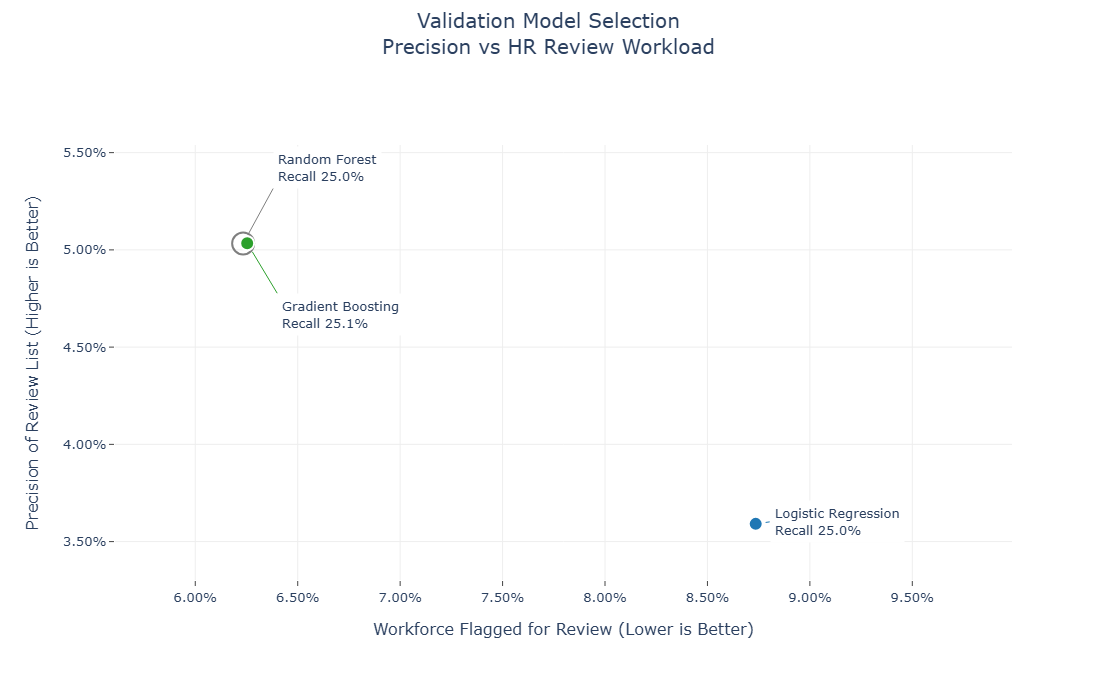

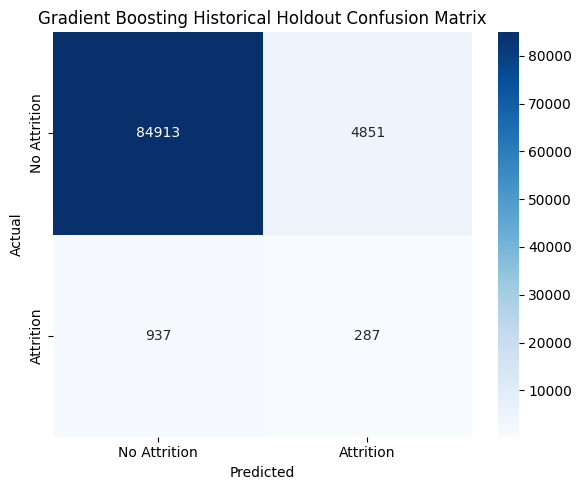

Selected-model historical holdout results by entity (large groups only):


,entity,records,attrition_cases,base_rate,average_precision,precision,recall,flagged_rate,lift
1,06,46770,587,0.0126,0.0367,0.0540,0.1789,0.0416,4.3035
0,01,37566,534,0.0142,0.0428,0.0504,0.2753,0.0777,3.5451
2,08,6494,103,0.0159,0.0697,0.1264,0.3398,0.0427,7.9664


In [32]:
from pathlib import Path


# Fix the model and cutoff before checking January.
validation_comparison_df = pd.DataFrame([
    lr_valid_metrics,
    rf_valid_metrics,
    gbm_valid_metrics,
])
validation_comparison_df["development_overfit_gap"] = [
    lr_cv_overfit_gap,
    rf_cv_overfit_gap,
    gbm_cv_overfit_gap,
]
validation_comparison_df["meets_recall_target"] = (
    validation_comparison_df["recall"] >= target_recall
)
validation_comparison_df["passes_overfit_guard"] = (
    validation_comparison_df["development_overfit_gap"] <= 0.05
)
eligible_models = validation_comparison_df.loc[
    validation_comparison_df["meets_recall_target"]
    & validation_comparison_df["passes_overfit_guard"]
].copy()

if len(eligible_models) > 0:
    selected_model_name = eligible_models.sort_values(
        ["precision", "flagged_rate", "average_precision"],
        ascending=[False, True, False],
    ).iloc[0]["model"]
    selection_reason = (
        "highest validation precision among models meeting the 25% recall target "
        "and the development overfitting safeguard; flagged rate and average "
        "precision break close results"
    )
else:
    selected_model_name = validation_comparison_df.sort_values(
        ["recall", "precision", "flagged_rate", "average_precision"],
        ascending=[False, False, True, False],
    ).iloc[0]["model"]
    selection_reason = (
        "fallback: highest validation recall because no model met the target"
    )

model_artifacts = {
    "Logistic Regression": {"model": lr_model, "threshold": lr_threshold},
    "Random Forest": {"model": rf_model, "threshold": rf_threshold},
    "Gradient Boosting": {"model": gbm_model, "threshold": gbm_threshold},
}
selected_artifacts = model_artifacts[selected_model_name]
best_model = selected_artifacts["model"]
best_threshold = selected_artifacts["threshold"]

print("Validation comparison used for model selection:")
display(validation_comparison_df.round(4))
print("Selected final model:", selected_model_name)
print("Selection reason:", selection_reason)
print("Selected operating threshold:", best_threshold)

# Replay January as an already-reviewed historical check.
lr_test_prob = lr_model.predict_proba(X_test[lr_model_features])[:, 1]
rf_test_prob = rf_model.predict_proba(X_test[rf_model_features])[:, 1]
gbm_test_prob = gbm_model.predict_proba(X_test[gbm_model_features])[:, 1]

lr_test_metrics, lr_test_pred = evaluate_at_threshold(
    "Logistic Regression", y_test, lr_test_prob, lr_threshold
)
rf_test_metrics, rf_test_pred = evaluate_at_threshold(
    "Random Forest", y_test, rf_test_prob, rf_threshold
)
gbm_test_metrics, gbm_test_pred = evaluate_at_threshold(
    "Gradient Boosting", y_test, gbm_test_prob, gbm_threshold
)
test_comparison_df = pd.DataFrame([
    lr_test_metrics,
    rf_test_metrics,
    gbm_test_metrics,
])

selected_test_predictions = {
    "Logistic Regression": (lr_test_prob, lr_test_pred, lr_test_metrics),
    "Random Forest": (rf_test_prob, rf_test_pred, rf_test_metrics),
    "Gradient Boosting": (gbm_test_prob, gbm_test_pred, gbm_test_metrics),
}
y_test_prob, y_test_pred, selected_test_metrics = selected_test_predictions[
    selected_model_name
]
y_valid_prob = {
    "Logistic Regression": lr_valid_prob,
    "Random Forest": rf_valid_prob,
    "Gradient Boosting": gbm_valid_prob,
}[selected_model_name]
y_valid_pred = {
    "Logistic Regression": lr_valid_pred,
    "Random Forest": rf_valid_pred,
    "Gradient Boosting": gbm_valid_pred,
}[selected_model_name]

print("Historical holdout comparison (replayed after selection):")
display(test_comparison_df.round(4))
print(f"{selected_model_name} classification report on historical holdout:")
print(classification_report(y_test, y_test_pred, zero_division=0))

# Compare training gaps and calendar results.
overfitting_diagnostic_df = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "cv_train_average_precision": [
        lr_cv_train_ap, rf_cv_train_ap, gbm_cv_train_ap
    ],
    "cv_validation_average_precision": [
        lr_cv_validation_ap, rf_cv_validation_ap, gbm_cv_validation_ap
    ],
    "cv_overfit_gap": [
        lr_cv_overfit_gap, rf_cv_overfit_gap, gbm_cv_overfit_gap
    ],
    "fixed_validation_average_precision": [
        lr_valid_metrics["average_precision"],
        rf_valid_metrics["average_precision"],
        gbm_valid_metrics["average_precision"],
    ],
    "final_test_average_precision": [
        lr_test_metrics["average_precision"],
        rf_test_metrics["average_precision"],
        gbm_test_metrics["average_precision"],
    ],
})
overfitting_diagnostic_df["diagnostic"] = np.select(
    [
        overfitting_diagnostic_df["cv_overfit_gap"] > 0.05,
        overfitting_diagnostic_df["cv_overfit_gap"] > 0.02,
    ],
    ["Large train-development gap", "Moderate train-development gap"],
    default="Limited train-development gap",
)


def best_search_snapshot_rows(search, model_name):
    rows = []
    selected_index = getattr(search, "selected_index_", search.best_index_)
    for fold_index, summary in tuning_snapshot_summary.iterrows():
        rows.append({
            "model": model_name,
            "stage": "Development check",
            "snapshot": pd.Timestamp(summary["validation_date"]),
            "average_precision": float(
                search.cv_results_[f"split{fold_index}_test_score"][
                    selected_index
                ]
            ),
        })
    return rows


calendar_performance_rows = []
for search, model_name in [
    (lr_search, "Logistic Regression"),
    (rf_search, "Random Forest"),
    (gbm_search, "Gradient Boosting"),
]:
    calendar_performance_rows.extend(
        best_search_snapshot_rows(search, model_name)
    )

for model_name, valid_metrics, test_metrics in [
    ("Logistic Regression", lr_valid_metrics, lr_test_metrics),
    ("Random Forest", rf_valid_metrics, rf_test_metrics),
    ("Gradient Boosting", gbm_valid_metrics, gbm_test_metrics),
]:
    calendar_performance_rows.extend([
        {
            "model": model_name,
            "stage": "Main validation",
            "snapshot": validation_date,
            "average_precision": valid_metrics["average_precision"],
        },
        {
            "model": model_name,
            "stage": "Historical holdout",
            "snapshot": test_date,
            "average_precision": test_metrics["average_precision"],
        },
    ])

calendar_performance_df = pd.DataFrame(calendar_performance_rows).sort_values(
    ["snapshot", "model"]
)
print("Overfitting diagnostic:")
display(overfitting_diagnostic_df.round(5))
print("Average precision across calendar snapshots:")
display(calendar_performance_df.round(5))

# Compare list precision with HR workload.
import plotly.graph_objects as go

model_colors = {
    "Logistic Regression": "#1f77b4",
    "Random Forest": "#7f7f7f",
    "Gradient Boosting": "#2ca02c",
}
model_selection_fig = go.Figure()
label_positions = {
    "Gradient Boosting": (30, -50, "left", "top"),
    "Random Forest": (30, 55, "left", "bottom"),
    "Logistic Regression": (14, 2, "left", "middle"),
}
for _, row in validation_comparison_df.iterrows():
    model_selection_fig.add_trace(go.Scatter(
        x=[row["flagged_rate"]],
        y=[row["precision"]],
        mode="markers",
        name=row["model"],
        marker=dict(
            size=22 if row["model"] == "Random Forest" else 14,
            symbol="circle-open" if row["model"] == "Random Forest" else "circle",
            color=model_colors[row["model"]],
            line=dict(color=model_colors[row["model"]] if row["model"] == "Random Forest" else "white", width=2),
        ),
        customdata=[[
            row["model"], row["recall"], row["tp"] + row["fp"],
            row["average_precision"], row["development_overfit_gap"],
        ]],
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>Workforce flagged: %{x:.2%}"
            "<br>Precision: %{y:.2%}<br>Recall: %{customdata[1]:.2%}"
            "<br>Records flagged: %{customdata[2]:,.0f}"
            "<br>Average precision: %{customdata[3]:.2%}"
            "<br>Development AP gap: %{customdata[4]:.2%}<extra></extra>"
        ),
        showlegend=False,
    ))
    dx, dy, ha, va = label_positions[row["model"]]
    model_selection_fig.add_annotation(
        x=row["flagged_rate"], y=row["precision"],
        text=f"{row['model']}<br>Recall {row['recall']:.1%}",
        showarrow=True, ax=dx, ay=-dy, xanchor=ha, yanchor=va,
        arrowhead=0, arrowwidth=1, arrowcolor=model_colors[row["model"]],
        standoff=10, bgcolor="rgba(255,255,255,0.95)", borderpad=4,
        align="left", font=dict(size=13),
    )
flagged_span = max(float(validation_comparison_df["flagged_rate"].max()
                         - validation_comparison_df["flagged_rate"].min()), 0.001)
precision_span = max(float(validation_comparison_df["precision"].max()
                           - validation_comparison_df["precision"].min()), 0.001)
model_selection_fig.update_layout(
    title=dict(text="Validation Model Selection<br>Precision vs HR Review Workload",
               x=0.5, y=0.97, xanchor="center", yanchor="top",
               pad=dict(t=8, b=15), font=dict(size=20)),
    template="plotly_white",
    width=1050,
    height=680,
    font=dict(size=13),
    margin=dict(l=115, r=85, t=145, b=100),
    hovermode="closest",
    xaxis=dict(
        title="Workforce Flagged for Review (Lower is Better)", tickformat=".2%",
        range=[validation_comparison_df["flagged_rate"].min() - flagged_span * 0.25,
               validation_comparison_df["flagged_rate"].max() + flagged_span * 0.50],
        gridcolor="#eeeeee", automargin=True,
        title_standoff=20, ticks="outside", ticklen=5,
    ),
    yaxis=dict(
        title="Precision of Review List (Higher is Better)", tickformat=".2%",
        range=[validation_comparison_df["precision"].min() - precision_span * 0.20,
               validation_comparison_df["precision"].max() + precision_span * 0.35],
        gridcolor="#eeeeee", automargin=True,
        title_standoff=20, ticks="outside", ticklen=5,
    ),
)
model_selection_fig.show()

# Count historical errors after fixing the validation choice.
selected_test_cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    selected_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{selected_model_name} Historical Holdout Confusion Matrix")
plt.tight_layout()
plt.show()


# Compare historical results across large entities.
subgroup_frame = pd.DataFrame({
    "entity": X_test["entity"].astype("string").fillna("Missing"),
    "actual": y_test.to_numpy(),
    "score": y_test_prob,
    "flagged": y_test_pred,
})
subgroup_rows = []
for entity_name, group in subgroup_frame.groupby("entity", dropna=False):
    if len(group) < 1_000 or group["actual"].sum() < 10:
        continue
    subgroup_precision = precision_score(
        group["actual"], group["flagged"], zero_division=0
    )
    subgroup_rows.append({
        "entity": entity_name,
        "records": len(group),
        "attrition_cases": int(group["actual"].sum()),
        "base_rate": group["actual"].mean(),
        "average_precision": average_precision_score(
            group["actual"], group["score"]
        ),
        "precision": subgroup_precision,
        "recall": recall_score(
            group["actual"], group["flagged"], zero_division=0
        ),
        "flagged_rate": group["flagged"].mean(),
        "lift": (
            subgroup_precision / group["actual"].mean()
            if group["actual"].mean() > 0 else np.nan
        ),
    })
subgroup_test_df = pd.DataFrame(subgroup_rows).sort_values(
    "records", ascending=False
)
print("Selected-model historical holdout results by entity (large groups only):")
display(subgroup_test_df.round(4))


**Gradient Boosting remains selected under the existing rule.** Its development gap is **4.52 percentage points**, versus **2.15** for Logistic Regression and **6.14** for Random Forest. Among eligible models, boosting has higher precision (**5.03% versus 3.59%**).

Boosting finds **287 of 1,142 cases (25.1%)**, versus **286 (25.0%)** for Logistic Regression. It needs **5,701 reviews**, **2,263 fewer (28.4%)**. This is approximately equal recall, not exactly the same case count. AP is **3.51% versus 2.67%**.

January remains mixed: boosting finds **287 of 1,224 cases (23.4%)**, with **5.59% precision**, **5.6% listed** and **4.09% AP**. Logistic Regression finds **296 cases (24.2%)**, with **4.34% precision** and **3.62% AP**.

Boosting uses **5,138 historical reviews**, versus **6,819**, but finds nine fewer cases. Higher precision and AP come with lower recall. January is an already-reviewed historical replay, not independent confirmation; keep Logistic Regression as a benchmark and test later untouched outcomes.

### 13.1 Comparing the Review Workload

Boosting finds **287 validation cases**, versus **286** for the other models, while needing **2,263 fewer reviews (28.4%)** than Logistic Regression. Random Forest needs **5,683 reviews** but fails the development-gap rule. The chart compares approximately equal recall under the same target.

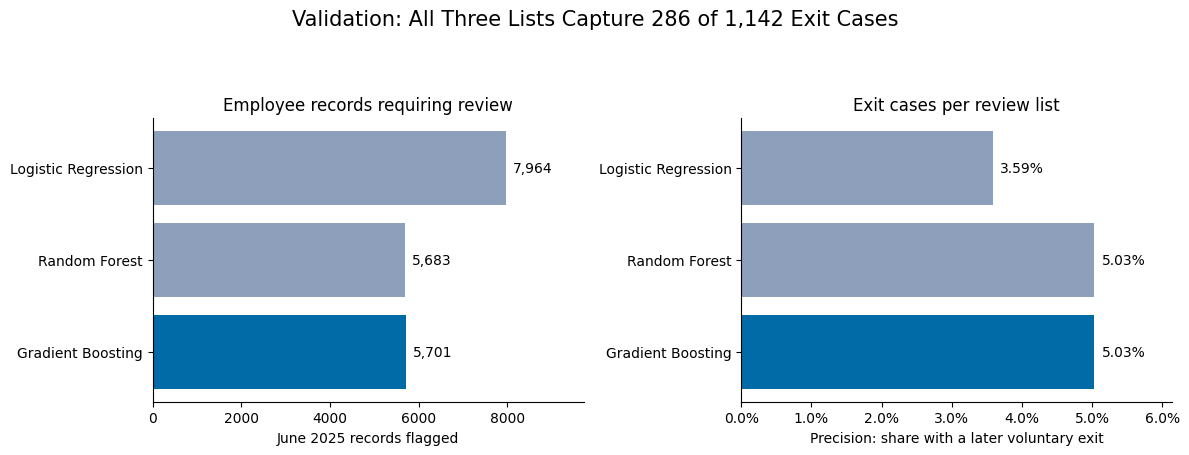

In [33]:
# Compare workload at the same validation recall.
review_plot = validation_comparison_df.copy()
review_plot["reviews"] = review_plot["tp"] + review_plot["fp"]
plot_colors = ["#8E9FBC" if name != "Gradient Boosting" else "#006BA6"
               for name in review_plot["model"]]
comparison_fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, field, title, formatter in [
    (axes[0], "reviews", "Employee records requiring review", lambda x: f"{x:,.0f}"),
    (axes[1], "precision", "Exit cases per review list", lambda x: f"{x:.2%}"),
]:
    ax.barh(review_plot["model"], review_plot[field], color=plot_colors)
    ax.invert_yaxis()
    ax.set_xlim(0, review_plot[field].max()*1.22)
    for i, value in enumerate(review_plot[field]):
        ax.text(value+review_plot[field].max()*.02, i, formatter(value), va="center")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_xlabel("June 2025 records flagged")
axes[1].set_xlabel("Precision: share with a later voluntary exit")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
comparison_fig.suptitle("Validation: All Three Lists Capture 286 of 1,142 Exit Cases", fontsize=15)
comparison_fig.tight_layout(rect=[0, 0, 1, .90])
plt.show()

### Connecting the Results to the Research Question

At the same list size, an untargeted list's expected exit count is its size multiplied by the workforce exit rate. This is a mathematical reference, not an intervention test.

The model finds **287 cases in 5,701 validation reviews**, versus about **71 expected on average** (71.4 before rounding), or **4.0 times** the concentration. It misses **855 of 1,142 cases**. Broad support remains important; the comparison does not measure exits prevented.

In [34]:
# Compare equally sized model and untargeted lists.
research_question_rows = []
for period_label, comparison in [
    ("June 2025 validation", validation_comparison_df),
    ("January 2026 historical check", test_comparison_df),
]:
    result = comparison.loc[comparison["model"].eq(selected_model_name)].iloc[0]
    reviews = int(result["tp"] + result["fp"])
    expected_untargeted_cases = reviews * float(result["base_rate"])
    research_question_rows.append({
        "Period": period_label,
        "Reviews in either list": reviews,
        "Model list: observed exit cases": int(result["tp"]),
        "Untargeted list: expected exit cases": expected_untargeted_cases,
        "Model list concentration vs untargeted": float(result["precision"] / result["base_rate"]),
        "Exit cases outside model list": int(result["fn"]),
    })
research_question_summary = pd.DataFrame(research_question_rows)
display(research_question_summary.round(1))

,Period,Reviews in either list,Model list: observed exit cases,Untargeted list: expected exit cases,Model list concentration vs untargeted,Exit cases outside model list
0,June 2025 validation,5701,287,71.4,4.0,855
1,January 2026 historical check,5138,287,69.1,4.2,937


### 13.2 Understanding the Errors and Group Differences

The historical list finds **287 exit cases**, includes **4,851 records without the target exit**, and misses **937 cases**. Across large reported entities, recall ranges from **17.9% to 34.0%**, with lift from **3.5 to 8.0**. Investigate these differences before use; they do not establish fairness or future consistency.

### 13.3 What This Analysis Can and Cannot Support

The ranking helps HR decide where to review. Scores are not calibrated departure probabilities, feature relationships are not causes, and no retention intervention has been evaluated.

Limits include only two development checks, repeated employee records and an already-reviewed holdout. Salary definitions, eligibility and scoring-time data availability also need checking.

Before use, I would test a later untouched period with complete outcomes and review sufficiently large workforce groups. A prospective comparison is still needed to learn whether the review process improves retention.

The two engineered binary flags also merge unknown values with negative conditions. I document that choice rather than changing fitted inputs without development evidence. A separate experiment should compare preserving unknown values or adding missingness indicators.

### 13.4 Assessing Statistical Uncertainty

The **95% Wilson intervals** estimate sampling uncertainty for January recall and precision at the fixed model and cutoff. They assume independent, comparable outcomes. Shared managers or local conditions can weaken that assumption, and January's prior review limits independent confirmation.

A 95% interval describes long-run coverage under those assumptions, not a 95% probability for this fixed population value. These intervals do not prove time stability, causation or superiority over Logistic Regression. Two-fold AP standard deviations describe variation across checks, not confidence intervals.

In [35]:
# Estimate historical uncertainty from aggregate counts.
from statistics import NormalDist

def wilson_interval(successes, trials, confidence=0.95):
    """Wilson score interval under a binomial working assumption."""
    z = NormalDist().inv_cdf((1+confidence)/2)
    p = successes / trials
    denominator = 1 + z*z/trials
    center = (p + z*z/(2*trials)) / denominator
    half_width = z*np.sqrt(p*(1-p)/trials + z*z/(4*trials*trials)) / denominator
    return center-half_width, center+half_width

historical_row = test_comparison_df.set_index("model").loc["Gradient Boosting"]
uncertainty_rows = []
for metric, denominator in [
    ("Recall: exit cases captured", int(historical_row["tp"] + historical_row["fn"])),
    ("Precision: exits among reviewed", int(historical_row["tp"] + historical_row["fp"])),
]:
    numerator = int(historical_row["tp"])
    low, high = wilson_interval(numerator, denominator)
    uncertainty_rows.append({"Historical measure": metric, "Cases": numerator,
        "Denominator": denominator, "Observed": numerator/denominator,
        "95% lower": low, "95% upper": high})
historical_uncertainty = pd.DataFrame(uncertainty_rows)
display(historical_uncertainty.style.format({"Observed": "{:.1%}",
    "95% lower": "{:.1%}", "95% upper": "{:.1%}"}))

,Historical measure,Cases,Denominator,Observed,95% lower,95% upper
0,Recall: exit cases captured,287,1224,23.4%,21.2%,25.9%
1,Precision: exits among reviewed,287,5138,5.6%,5.0%,6.2%


January's recall interval includes the 25% target, but that does not show stable achievement or model equivalence. Both classifiers score the same employees, so an independent-proportions test would be inappropriate. I would assess paired predictions and new outcomes before claiming an advantage.

## 14. Explaining the Selected Model and Scoring the Current Workforce

**Permutation importance** measures the AP change after shuffling an input. The corrected check uses one fixed, stratified sample of **20,000 validation records**, with **251 exit cases**, for both the unshuffled baseline and every shuffle. `max_samples=1.0` prevents a full-data baseline from being compared with subsampled shuffled scores. I use **ten repeats**; the sample baseline AP is **3.4829%**.

Salary and tenure have the largest measured changes, followed by their interaction. The interaction varies substantially across shuffles. Three unused indicators have zero importance. Repeat standard deviations describe shuffle variability, not confidence intervals or causal effects; overlapping inputs and sampling still limit interpretation. The old full-versus-subsample importance estimates are superseded.

For **90,493 September 30, 2026 records**, the unchanged model cutoff places **4,987 employees (5.5%)** in High and **23,382 (25.8%)** in Medium. Medium begins at half the High cutoff as a monitoring convention. Scores and bands describe review priority, not departure probabilities or expected exits.

In [39]:
# Show the selected model's input-check results.
preprocess_fitted = best_model.named_steps["preprocess"]
clf_fitted = best_model.named_steps["clf"]

feature_names = list(final_num_features)
if len(final_cat_features) > 0 and "cat" in preprocess_fitted.named_transformers_:
    cat_transformer = preprocess_fitted.named_transformers_["cat"]
    if hasattr(cat_transformer, "named_steps") and "onehot" in cat_transformer.named_steps:
        cat_ohe = cat_transformer.named_steps["onehot"]
        feature_names = feature_names + list(
            cat_ohe.get_feature_names_out(final_cat_features)
        )

if hasattr(clf_fitted, "coef_"):
    importance_df = (
        pd.DataFrame({
            "feature": feature_names,
            "importance": clf_fitted.coef_[0],
            "importance_type": "logistic_coefficient",
        })
        .assign(abs_importance=lambda d: d["importance"].abs())
        .sort_values("abs_importance", ascending=False)
    )
elif hasattr(clf_fitted, "feature_importances_"):
    importance_df = (
        pd.DataFrame({
            "feature": feature_names,
            "importance": clf_fitted.feature_importances_,
            "importance_type": "random_forest_feature_importance",
        })
        .assign(abs_importance=lambda d: d["importance"].abs())
        .sort_values("importance", ascending=False)
    )
else:
    # Shuffle each input and check the ranking change.
    from sklearn.inspection import permutation_importance

    from sklearn.model_selection import train_test_split
    from threadpoolctl import threadpool_limits

    # Use the same fixed records for the baseline and every shuffle.
    permutation_sample_size = min(20_000, len(X_valid))
    permutation_indices = np.arange(len(X_valid))
    if permutation_sample_size < len(X_valid):
        permutation_indices, _ = train_test_split(
            permutation_indices,
            train_size=permutation_sample_size,
            stratify=np.asarray(y_valid),
            random_state=RANDOM_STATE,
        )
    permutation_X = X_valid[final_model_features].iloc[permutation_indices].copy()
    permutation_y = y_valid.iloc[permutation_indices].copy()

    with threadpool_limits(limits=2):
        permutation_baseline_ap = average_precision_score(
            permutation_y, best_model.predict_proba(permutation_X)[:, 1]
        )
        permutation = permutation_importance(
            best_model,
            permutation_X,
            permutation_y,
            scoring="average_precision",
            n_repeats=10,
            random_state=RANDOM_STATE,
            n_jobs=1,
            max_samples=1.0,
        )
    print("Feature-check sample:", len(permutation_X), "validation records")
    print("Feature-check exit cases:", int(permutation_y.sum()))
    print("Unshuffled sample AP:", f"{permutation_baseline_ap:.4%}")
    print("Shuffles per input: 10; baseline and shuffles use the same sample.")

    importance_df = (
        pd.DataFrame({
            "feature": final_model_features,
            "importance": permutation.importances_mean,
            "importance_std": permutation.importances_std,
            "importance_type": "permutation_importance",
        })
        .assign(abs_importance=lambda d: d["importance"].abs())
        .sort_values("abs_importance", ascending=False)
    )

coef_df = importance_df.copy()

print("Selected model:", selected_model_name)
print("Selected feature set:", final_feature_set_name)
print("Input sensitivity by absolute importance (not causal drivers):")
display(importance_df.head(15))

# Show score direction for Logistic Regression weights.
if selected_model_name == "Logistic Regression":
    coefficient_labels = {
        "annual_salary": "Annual salary",
        "tenure_months": "Employee tenure",
        "low_performer": "Low-performer status",
        "mgr_avg_team_tenure": "Manager team tenure",
        "mgr_attrition_6mo_rate": "Manager turnover (6 mo)",
        "mgr_attrition_12mo_rate": "Manager turnover (12 mo)",
        "underpaid_flag": "Pay below peer benchmark",
        "high_mgr_attrition": "Any prior manager turnover",
    }
    coefficient_plot = importance_df.copy()
    coefficient_plot["feature_label"] = coefficient_plot["feature"].map(
        coefficient_labels
    ).fillna(coefficient_plot["feature"])
    coefficient_plot = coefficient_plot.sort_values("importance")
    coefficient_colors = np.where(
        coefficient_plot["importance"] > 0,
        "#CB333B",
        "#006BA6",
    )

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(
        coefficient_plot["feature_label"],
        coefficient_plot["importance"],
        color=coefficient_colors,
    )
    ax.axvline(0, color="#5A5A5A", linewidth=1)
    ax.set_title("Selected Logistic Regression Coefficients")
    ax.set_xlabel("Standardized Coefficient (Direction of Model Score)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.15)
    sns.despine(ax=ax)
    plt.tight_layout()

    plt.show()


Feature-check sample: 20000 validation records
Feature-check exit cases: 251
Unshuffled sample AP: 3.4829%
Shuffles per input: 10; baseline and shuffles use the same sample.
Selected model: Gradient Boosting
Selected feature set: All candidate numeric features
Input sensitivity by absolute importance (not causal drivers):


,feature,importance,importance_std,importance_type,abs_importance
0,annual_salary,0.009721,0.002288,permutation_importance,0.009721
3,tenure_months,0.003698,0.000756,permutation_importance,0.003698
12,compa_tenure_interaction,0.002937,0.002643,permutation_importance,0.002937
5,mgr_team_size,0.001775,0.000688,permutation_importance,0.001775
8,mgr_attrition_6mo_rate,0.000776,0.000776,permutation_importance,0.000776
2,performance_rating,0.000460,0.001340,permutation_importance,0.000460
9,mgr_attrition_12mo_rate,0.000383,0.000198,permutation_importance,0.000383
6,mgr_avg_team_tenure,0.000043,0.000296,permutation_importance,0.000043
1,compa_ratio,0.000027,0.000148,permutation_importance,0.000027
7,mgr_low_perf_pct,0.000012,0.000029,permutation_importance,0.000012


In [37]:
# Score the latest snapshot for HR review.
latest_snapshot = df.loc[
    df["snapshot_date"] == df["snapshot_date"].max()
].copy()

id_cols = ["nuid", "manager_nuid"]
available_id_cols = [col for col in id_cols if col in latest_snapshot.columns]
latest_ids = latest_snapshot[available_id_cols].copy() if available_id_cols else pd.DataFrame(index=latest_snapshot.index)

latest_snapshot_model = latest_snapshot.copy()
latest_snapshot_model["snapshot_date"] = pd.to_datetime(latest_snapshot_model["snapshot_date"])

# Keep the fitted flag convention at scoring time, including its missing-value limitation.
latest_snapshot_model["underpaid_flag"] = (
    latest_snapshot_model["compa_ratio"] < 1
).astype(int)

latest_snapshot_model["high_mgr_attrition"] = (
    latest_snapshot_model["mgr_attrition_12mo_rate"].fillna(0) > 0
).astype(int)

latest_snapshot_model["compa_tenure_interaction"] = (
    latest_snapshot_model["compa_ratio"] * latest_snapshot_model["tenure_months"]
)

latest_snapshot_model = latest_snapshot_model.replace([np.inf, -np.inf], np.nan)

missing_score_features = [col for col in final_model_features if col not in latest_snapshot_model.columns]
if missing_score_features:
    raise ValueError(f"Scoring data is missing model features: {missing_score_features}")

latest_x = latest_snapshot_model[final_model_features].copy()
print("Scoring dataset shape:", latest_x.shape)

latest_snapshot["attrition_risk"] = best_model.predict_proba(latest_x)[:, 1]

if available_id_cols:
    latest_snapshot[available_id_cols] = latest_ids

high_threshold = best_threshold
# Keep High fixed; use Medium as a monitoring convention.
medium_threshold = high_threshold * 0.5

latest_snapshot["risk_band"] = np.select(
    [
        latest_snapshot["attrition_risk"] >= high_threshold,
        latest_snapshot["attrition_risk"] >= medium_threshold,
    ],
    ["High", "Medium"],
    default="Low",
)

risk_band_summary = (
    latest_snapshot["risk_band"]
    .value_counts(dropna=False)
    .rename_axis("risk_band")
    .reset_index(name="employees")
)
risk_band_summary["share"] = risk_band_summary["employees"] / len(latest_snapshot)

print("High threshold:", high_threshold)
print("Medium threshold:", medium_threshold)
display(risk_band_summary)


Scoring dataset shape: (90493, 13)
High threshold: 0.7576879216219221
Medium threshold: 0.37884396081096106


,risk_band,employees,share
0,Low,62124,0.686506
1,Medium,23382,0.258385
2,High,4987,0.055109


### 14.1 Translating Current Rankings into Questions for HR

September 2026 outcomes are still unknown. The **4,987 High-band employees** average **3.0 years** of tenure and **$80,834** recorded annual salary, versus **15.3 years** and **$138,477** in Low. Confirm pay definitions, hours and job mix before interpreting the contrast.

Manager history is partly available: **7.0%** of six-month and **11.8%** of twelve-month values are missing. Remaining gaps need investigation, particularly because the turnover flag currently maps missing history to zero.

Nursing has **1,590 High-band employees among 26,692 (6.0%)**; Patient Care Srvs (Non-Nurse) has **1,087 among 16,639 (6.5%)**; Facilities Services has **296 among 4,194 (7.1%)**. The table shows the five largest High-band counts among groups with at least 1,000 employees. Counts help plan workload; shares provide group-size context, not causes or fairness.

**HR follow-up:** Verify eligibility and remaining data gaps, then agree on ownership and capacity. Scores cannot reveal employee intentions.

In [38]:
# Summarize current review needs using the existing scores.
current_review_frame = latest_snapshot.assign(
    high_review_priority=latest_snapshot["risk_band"].eq("High"),
    tenure_years=latest_snapshot["tenure_months"] / 12,
)
current_band_profile = current_review_frame.groupby("risk_band").agg(
    employees=("risk_band", "size"),
    average_tenure_years=("tenure_years", "mean"),
    average_recorded_annual_salary=("annual_salary", "mean"),
).reindex(["Low", "Medium", "High"])
print("Current workforce profile by review-priority band:")
display(current_band_profile.round(1))

current_job_family_review = current_review_frame.groupby("job_family", dropna=False).agg(
    employees=("risk_band", "size"),
    high_band_employees=("high_review_priority", "sum"),
)
current_job_family_review["high_band_share_pct"] = (
    100 * current_job_family_review["high_band_employees"]
    / current_job_family_review["employees"]
)
current_job_family_review = current_job_family_review.loc[
    current_job_family_review["employees"].ge(1_000)
].sort_values("high_band_employees", ascending=False).head(5)
print("Current job-family review workload (groups of at least 1,000 employees):")
display(current_job_family_review.round(1))

Current workforce profile by review-priority band:


,employees,average_tenure_years,average_recorded_annual_salary
risk_band,,,
Low,62124,15.3,138477.3
Medium,23382,4.4,101329.2
High,4987,3.0,80834.3


Current job-family review workload (groups of at least 1,000 employees):


,employees,high_band_employees,high_band_share_pct
job_family,,,
Nursing (Licensed),26692,1590,6.0
Patient Care Srvs (Non-Nurse),16639,1087,6.5
Administrative Support,5962,352,5.9
Facilities Services,4194,296,7.1
Pharmaceutical Services,5962,295,4.9


## 15. Saving the Internal Handoff

An authorized rerun saves five internal CSVs to `Capstone/Final Report/outputs`: current scores, feature checks, validation results, historical results and the split summary. These support the HR insights notebook. Employee-level exports belong in the approved internal environment, outside any public submission.

The submission includes the executed notebook, README and aggregate figures. Working files and backups stay outside the submission folder. Operational use would also need the fitted pipeline, environment and model metadata.

`model_run_manifest.json` records the selected settings, cutoff, software versions and export fingerprints. It contains aggregate metadata only and ties this report to one saved run.

In [39]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the five exports for the HR insights notebook.
latest_snapshot.to_csv(
    output_dir / "attrition_latest_snapshot_scored.csv", index=False
)
importance_df.to_csv(
    output_dir / "attrition_model_feature_importance.csv", index=False
)
validation_comparison_df.to_csv(
    output_dir / "model_validation_comparison.csv", index=False
)
test_comparison_df.to_csv(
    output_dir / "model_test_comparison.csv", index=False
)
model_split_summary_df.to_csv(
    output_dir / "model_split_summary.csv", index=False
)

print("Saved outputs used by attrition_insights_reg:")
print(output_dir / "attrition_latest_snapshot_scored.csv")
print(output_dir / "attrition_model_feature_importance.csv")
print(output_dir / "model_validation_comparison.csv")
print(output_dir / "model_test_comparison.csv")
print(output_dir / "model_split_summary.csv")

# Keep a record of the run used for this report.
import json
import hashlib
import platform
import sklearn
from datetime import datetime, timezone

export_names = [
    "attrition_latest_snapshot_scored.csv",
    "attrition_model_feature_importance.csv",
    "model_validation_comparison.csv",
    "model_test_comparison.csv",
    "model_split_summary.csv",
]
run_manifest = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "random_state": int(RANDOM_STATE),
    "selected_model": selected_model_name,
    "selected_threshold": float(best_threshold),
    "selected_features": list(final_model_features),
    "selected_classifier_parameters": best_model.named_steps["clf"].get_params(),
    "calendar_splits": model_split_summary_df.to_dict(orient="records"),
    "validation_results": validation_comparison_df.to_dict(orient="records"),
    "historical_results": test_comparison_df.to_dict(orient="records"),
    "historical_check_already_reviewed": True,
    "scoring_snapshot": str(latest_snapshot["snapshot_date"].max()),
    "scored_records": int(len(latest_snapshot)),
    "flag_missingness_convention": "Unknown pay-position and manager-history flags map to zero in this fitted version.",
    "permutation_check": {
        "sample_records": int(len(permutation_X)),
        "exit_cases": int(permutation_y.sum()),
        "baseline_ap": float(permutation_baseline_ap),
        "repeats": 10,
        "max_samples": 1.0,
        "sampling": "Fixed stratified validation sample",
    },
    "export_sha256": {
        name: hashlib.sha256((output_dir / name).read_bytes()).hexdigest()
        for name in export_names
    },
}
(output_dir / "model_run_manifest.json").write_text(
    json.dumps(run_manifest, indent=2, default=str), encoding="utf-8"
)
print("Saved run settings and export fingerprints: model_run_manifest.json")


Saved outputs used by attrition_insights_reg:
outputs\attrition_latest_snapshot_scored.csv
outputs\attrition_model_feature_importance.csv
outputs\model_validation_comparison.csv
outputs\model_test_comparison.csv
outputs\model_split_summary.csv
Saved run settings and export fingerprints: model_run_manifest.json


### 15.1 Following the Model as the Workforce Changes

Deployment is outside this capstone. A future workflow would need these checks:

1. **Check each file.** Review dates, counts, duplicates, missing inputs and unusual values, especially pay. Investigate sudden band-size changes.
2. **Measure mature outcomes.** Once six-month outcomes and source coverage are complete, recalculate AP, recall, precision, lift and workload.
3. **Review workforce groups.** Investigate differences in data quality, performance and potential unfair impact where groups are large enough.
4. **Keep a model record.** Save dates, inputs, settings and cutoff. Deterioration should trigger review rather than automatic model changes.

### 15.2 The Decisions I Would Make Next

I would check with HR teams whether **5,701 validation reviews** is realistic for finding about one-quarter of cases. Current list sizes may differ.

Before a pilot, verify eligibility, pay definitions, hours and remaining manager-history gaps. Freeze the model and cutoff, then test later untouched outcomes and group differences.

For a small pilot, agree on ownership and response time. Measure review effectiveness and workload volume first, then assess mature exits against a suitable comparison group. We still need to test whether support improves retention.

## 16. What I Learned and What It Means for HR

Gradient Boosting finds **287 June validation cases (25.1%)**, with **5.03% precision** and **6.3% listed**. It needs **2,263 fewer reviews (28.4%)** than Logistic Regression while finding one additional case. The list has **4.0 times** the untargeted exit concentration.

January is mixed: boosting has lower recall (**23.4% versus 24.2%**), but higher precision (**5.59% versus 4.34%**) and AP (**4.09% versus 3.62%**). These results support prioritization, not general superiority or deployment readiness.

**Answer to the problem statement:** The ranking provides a more concentrated starting list in this population. The corrected sensitivity check and workforce profiles help frame HR questions, without establishing causes or effective interventions.

Keep this run's inputs, model settings, cutoff and exports together. Next, verify data gaps and flag handling, test later untouched outcomes, and agree on a manageable HR trial. Whether support improves retention still needs evaluation.